# SETUP CƠ BẢN

## CÀI THƯ VIỆN

In [3]:
# Cài đặt TẤT CẢ thư viện cần thiết
!pip install --upgrade ultralytics -q
!pip install opencv-python pillow scikit-learn pyyaml tqdm matplotlib -q

You should consider upgrading via the 'C:\Users\K0HEI\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.
You should consider upgrading via the 'C:\Users\K0HEI\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


## IMPORT THƯ VIỆN

In [1]:
"""
=============================================================================
PIPELINE HOÀN CHỈNH: OBJECT DETECTION VỚI YOLOV8
=============================================================================
"""

# =============================================================================
# PHẦN 1: CÀI ĐẶT THƯ VIỆN
# =============================================================================

print("="*80)
print("BƯỚC 1: CÀI ĐẶT THƯ VIỆN")
print("="*80)

print("\n⏳ Đang import thư viện...")

import os
import shutil
import random
import yaml
from pathlib import Path
from sklearn.model_selection import train_test_split
import cv2
from PIL import Image
import numpy as np
from ultralytics import YOLO
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from glob import glob
from tqdm import tqdm

# Kiểm tra GPU
print(f"\n✓ CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"✓ GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"✓ VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("⚠️  Đang sử dụng CPU - Training sẽ chậm!")

print("\n✓ Đã cài đặt xong tất cả thư viện!")

BƯỚC 1: CÀI ĐẶT THƯ VIỆN

⏳ Đang import thư viện...

✓ CUDA available: True
✓ GPU Device: NVIDIA GeForce RTX 2060 SUPER
✓ VRAM: 8.00 GB

✓ Đã cài đặt xong tất cả thư viện!


## CẤU HÌNH CƠ BẢN

In [2]:
# =============================================================================
# CELL 2: CẤU HÌNH - THAY ĐỔI PHẦN NÀY
# =============================================================================

print("="*80)
print("CELL 2: CẤU HÌNH")
print("="*80)

# ==================== THAY ĐỔI CẤU HÌNH Ở ĐÂY ====================

# ĐƯỜNG DẪN DATASET
ORIGINAL_DATASET_PATH = r"D:\Stuffs\ThiGiacMayTinh\DoAnTGMT"                                   # ← Dataset gốc
OUTPUT_DATASET_PATH = r"D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\data"          # ← Dataset mới sau khi chia

# TỶ LỆ CHIA DATASET
TRAIN_RATIO = 0.7   # 70% train
VAL_RATIO = 0.20     # 20% valid
TEST_RATIO = 0.10    # 10% test

# CẤU HÌNH TRAINING
MODEL_NAME = 'yolo26s.pt'      # Tên tệp mô hình gốc (yolo26 phiên bản small, định dạng .pt)
EPOCHS = 100                  # Số lượt huấn luyện toàn bộ tập dữ liệu (100 lần)
BATCH_SIZE = 16                # Số lượng hình ảnh máy học cùng lúc trong mỗi bước lặp
IMG_SIZE = 640                # Kích thước hình ảnh đầu vào (resize về dạng 640x640 pixel)
DEVICE = '0'                  # Lựa chọn thiết bị chạy: '0' là GPU (card đồ họa), 'cpu' là CPU
PROJECT_NAME = 'runs/detect'  # Đường dẫn thư mục chính để lưu kết quả huấn luyện
EXPERIMENT_NAME = 'yolo26s_traffic' # Tên cụ thể của đợt thử nghiệm này (để phân biệt với các lần chạy khác)

# CLASS NAMES 
MANUAL_CLASS_NAMES = ['Bike', 'Bus', 'Car', 'Motorbike', 'Truck']
# =================================================================

print(f"\n✓ Dataset gốc: {ORIGINAL_DATASET_PATH}")
print(f"✓ Dataset mới: {OUTPUT_DATASET_PATH}")
print(f"✓ Tỷ lệ: {TRAIN_RATIO*100:.0f}% | {VAL_RATIO*100:.0f}% | {TEST_RATIO*100:.0f}%")
print(f"✓ Model: {MODEL_NAME}")
print(f"✓ Epochs: {EPOCHS}")
print(f"✓ Batch Size: {BATCH_SIZE}")
print(f"✓ Image Size: {IMG_SIZE}")
print(f"✓ Device: {DEVICE}")
print(f"✓ Project Name: {PROJECT_NAME}")
print(f"✓ Experiment Name: {EXPERIMENT_NAME}")
print("\n✅ Cấu hình hoàn tất!")

CELL 2: CẤU HÌNH

✓ Dataset gốc: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT
✓ Dataset mới: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\data
✓ Tỷ lệ: 70% | 20% | 10%
✓ Model: yolo26s.pt
✓ Epochs: 100
✓ Batch Size: 16
✓ Image Size: 640
✓ Device: 0
✓ Project Name: runs/detect
✓ Experiment Name: yolo26s_traffic

✅ Cấu hình hoàn tất!


## GỘP ẢNH

In [3]:
# =============================================================================
# CELL 3: GỘP TẤT CẢ ẢNH TỪ TRAIN/VAL/TEST
# =============================================================================

print("="*80)
print("CELL 3: GỘP TẤT CẢ ẢNH")
print("="*80)

# Tạo thư mục tạm
temp_dir = os.path.join(OUTPUT_DATASET_PATH, '_temp')
temp_images_dir = os.path.join(temp_dir, 'all_images')
temp_labels_dir = os.path.join(temp_dir, 'all_labels')

# Xóa nếu đã tồn tại
if os.path.exists(temp_images_dir):
    shutil.rmtree(temp_images_dir)
if os.path.exists(temp_labels_dir):
    shutil.rmtree(temp_labels_dir)

os.makedirs(temp_images_dir, exist_ok=True)
os.makedirs(temp_labels_dir, exist_ok=True)

# Gộp ảnh
image_counter = 0
stats = {}

possible_splits = ['train', 'training', 'valid', 'validation', 'val', 'test', 'testing']

print("\n🔄 Bắt đầu gộp ảnh...")

for split in possible_splits:
    img_dir = os.path.join(ORIGINAL_DATASET_PATH, split, 'images')
    lbl_dir = os.path.join(ORIGINAL_DATASET_PATH, split, 'labels')
    
    if not os.path.exists(img_dir):
        continue
    
    images = [f for f in os.listdir(img_dir) 
             if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    
    if len(images) == 0:
        continue
    
    print(f"\n📂 {split.upper()}: {len(images)} ảnh")
    stats[split] = len(images)
    
    for img_name in tqdm(images, desc=f"  Copy {split}"):
        src_img = os.path.join(img_dir, img_name)
        label_name = os.path.splitext(img_name)[0] + '.txt'
        src_lbl = os.path.join(lbl_dir, label_name)
        
        # Tên mới
        ext = os.path.splitext(img_name)[1]
        new_img_name = f"image_{image_counter:06d}{ext}"
        new_lbl_name = f"image_{image_counter:06d}.txt"
        
        dst_img = os.path.join(temp_images_dir, new_img_name)
        dst_lbl = os.path.join(temp_labels_dir, new_lbl_name)
        
        # Copy
        shutil.copy2(src_img, dst_img)
        
        if os.path.exists(src_lbl):
            shutil.copy2(src_lbl, dst_lbl)
        
        image_counter += 1

# Thống kê
print(f"\n{'='*80}")
print("📊 THỐNG KÊ:")
print(f"{'='*80}")
for split, count in stats.items():
    print(f"  {split.upper():<12}: {count:>5} ảnh")
print(f"  {'TỔNG':<12}: {image_counter:>5} ảnh")
print(f"{'='*80}")

total_images = image_counter

print(f"\n✅ Đã gộp {total_images} ảnh!")
print(f"   📁 Images: {temp_images_dir}")
print(f"   📁 Labels: {temp_labels_dir}")

CELL 3: GỘP TẤT CẢ ẢNH

🔄 Bắt đầu gộp ảnh...

📂 TRAIN: 28409 ảnh


  Copy train: 100%|██████████| 28409/28409 [05:45<00:00, 82.25it/s] 



📂 VALID: 3203 ảnh


  Copy valid: 100%|██████████| 3203/3203 [00:41<00:00, 78.11it/s]



📂 TEST: 904 ảnh


  Copy test: 100%|██████████| 904/904 [00:11<00:00, 77.91it/s]


📊 THỐNG KÊ:
  TRAIN       : 28409 ảnh
  VALID       :  3203 ảnh
  TEST        :   904 ảnh
  TỔNG        : 32516 ảnh

✅ Đã gộp 32516 ảnh!
   📁 Images: D:\Stuffs\ThiGiacMayTinh\HocSau\Weapon\_temp\all_images
   📁 Labels: D:\Stuffs\ThiGiacMayTinh\HocSau\Weapon\_temp\all_labels


## CHIA LẠI ẢNH

In [4]:
# =============================================================================
# CELL 4: CHIA LẠI DATASET THEO TỶ LỆ
# =============================================================================

print("="*80)
print("CELL 4: CHIA DATASET THEO TỶ LỆ")
print("="*80)

# Kiểm tra tỷ lệ
total_ratio = TRAIN_RATIO + VAL_RATIO + TEST_RATIO
if abs(total_ratio - 1.0) > 0.001:
    print(f"❌ Lỗi: Tổng tỷ lệ = {total_ratio}, phải bằng 1.0!")
else:
    # Set seed
    random.seed(42)
    np.random.seed(42)
    
    # Tạo thư mục
    print("\n📁 Tạo cấu trúc thư mục...")
    for split in ['train', 'val', 'test']:
        os.makedirs(os.path.join(OUTPUT_DATASET_PATH, split, 'images'), exist_ok=True)
        os.makedirs(os.path.join(OUTPUT_DATASET_PATH, split, 'labels'), exist_ok=True)
    
    # Lấy danh sách ảnh
    all_images = [f for f in os.listdir(temp_images_dir) 
                  if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    
    print(f"✓ Tổng: {len(all_images)} ảnh")
    
    # Shuffle
    random.shuffle(all_images)
    
    # Chia
    total = len(all_images)
    train_size = int(total * TRAIN_RATIO)
    val_size = int(total * VAL_RATIO)
    test_size = total - train_size - val_size
    
    train_images = all_images[:train_size]
    val_images = all_images[train_size:train_size + val_size]
    test_images = all_images[train_size + val_size:]
    
    print(f"\n{'='*80}")
    print("📊 PHÂN CHIA:")
    print(f"{'='*80}")
    print(f"  🟢 TRAIN: {len(train_images):>5} ảnh ({TRAIN_RATIO*100:.1f}%)")
    print(f"  🟡 VAL:   {len(val_images):>5} ảnh ({VAL_RATIO*100:.1f}%)")
    print(f"  🔴 TEST:  {len(test_images):>5} ảnh ({TEST_RATIO*100:.1f}%)")
    print(f"{'='*80}")
    
    # Copy files
    splits = {
        'train': train_images,
        'val': val_images,
        'test': test_images
    }
    
    for split_name, image_list in splits.items():
        if len(image_list) == 0:
            continue
        
        print(f"\n📁 Copy {split_name.upper()}...")
        
        for img_name in tqdm(image_list, desc=f"  {split_name}"):
            src_img = os.path.join(temp_images_dir, img_name)
            dst_img = os.path.join(OUTPUT_DATASET_PATH, split_name, 'images', img_name)
            shutil.copy2(src_img, dst_img)
            
            label_name = os.path.splitext(img_name)[0] + '.txt'
            src_lbl = os.path.join(temp_labels_dir, label_name)
            dst_lbl = os.path.join(OUTPUT_DATASET_PATH, split_name, 'labels', label_name)
            
            if os.path.exists(src_lbl):
                shutil.copy2(src_lbl, dst_lbl)
    
    # Xóa thư mục tạm
    if os.path.exists(temp_dir):
        shutil.rmtree(temp_dir)
        print(f"\n🗑️  Đã xóa thư mục tạm")
    
    print(f"\n✅ Chia dataset xong!")
    print(f"   📁 Dataset mới: {OUTPUT_DATASET_PATH}")

CELL 4: CHIA DATASET THEO TỶ LỆ

📁 Tạo cấu trúc thư mục...
✓ Tổng: 32516 ảnh

📊 PHÂN CHIA:
  🟢 TRAIN: 22761 ảnh (70.0%)
  🟡 VAL:    4877 ảnh (15.0%)
  🔴 TEST:   4878 ảnh (15.0%)

📁 Copy TRAIN...


  train: 100%|██████████| 22761/22761 [04:34<00:00, 83.04it/s]



📁 Copy VAL...


  val: 100%|██████████| 4877/4877 [00:57<00:00, 84.99it/s]



📁 Copy TEST...


  test: 100%|██████████| 4878/4878 [01:03<00:00, 76.70it/s]



🗑️  Đã xóa thư mục tạm

✅ Chia dataset xong!
   📁 Dataset mới: D:\Stuffs\ThiGiacMayTinh\HocSau\Weapon


## TẠO FILE DATA.YAML

In [22]:
# =============================================================================
# CELL 5: TẠO FILE DATA.YAML
# =============================================================================

print("="*80)
print("CELL 5: TẠO DATA.YAML")
print("="*80)

# Lấy class names
if MANUAL_CLASS_NAMES is not None:
    class_names = MANUAL_CLASS_NAMES
    print(f"✓ Dùng class names thủ công: {class_names}")
else:
    # Đọc từ data.yaml gốc
    yaml_path_old = os.path.join(ORIGINAL_DATASET_PATH, 'data.yaml')
    
    if os.path.exists(yaml_path_old):
        with open(yaml_path_old, 'r', encoding='utf-8') as f:
            data_old = yaml.safe_load(f)
        class_names = data_old.get('names', [])
        print(f"✓ Đọc từ data.yaml gốc: {class_names}")
    else:
        print("❌ Không tìm thấy data.yaml gốc!")
        print("Vui lòng nhập class names thủ công ở CELL 2 (MANUAL_CLASS_NAMES)")
        class_names = None

if class_names:
    # Tạo data.yaml mới
    yaml_path = os.path.join(OUTPUT_DATASET_PATH, 'data.yaml')
    
    data = {
        'path': OUTPUT_DATASET_PATH,
        'train': 'train/images',
        'val': 'val/images',
        'test': 'test/images',
        'nc': len(class_names),
        'names': class_names
    }
    
    with open(yaml_path, 'w', encoding='utf-8') as f:
        yaml.dump(data, f, sort_keys=False, default_flow_style=False, allow_unicode=True)
    
    print(f"\n{'='*80}")
    print("📄 ĐÃ TẠO DATA.YAML")
    print(f"{'='*80}")
    print(f"  File: {yaml_path}")
    print(f"  Classes ({len(class_names)}): {class_names}")
    print(f"{'='*80}")
    
    print(f"\n✅ Tạo data.yaml thành công!")

CELL 5: TẠO DATA.YAML
✓ Dùng class names thủ công: ['Grenade', 'Handgun', 'Rifle', 'Steel arms']

📄 ĐÃ TẠO DATA.YAML
  File: D:\Stuffs\ThiGiacMayTinh\HocSau\Weapon\data.yaml
  Classes (4): ['Grenade', 'Handgun', 'Rifle', 'Steel arms']

✅ Tạo data.yaml thành công!


## ĐẾM BOUNDING BOX

⏳ Đang quét và đếm số lượng Bounding Box...
✅ Train: Tìm thấy 44676 objects.
✅ Val: Tìm thấy 12950 objects.
✅ Test: Tìm thấy 6730 objects.


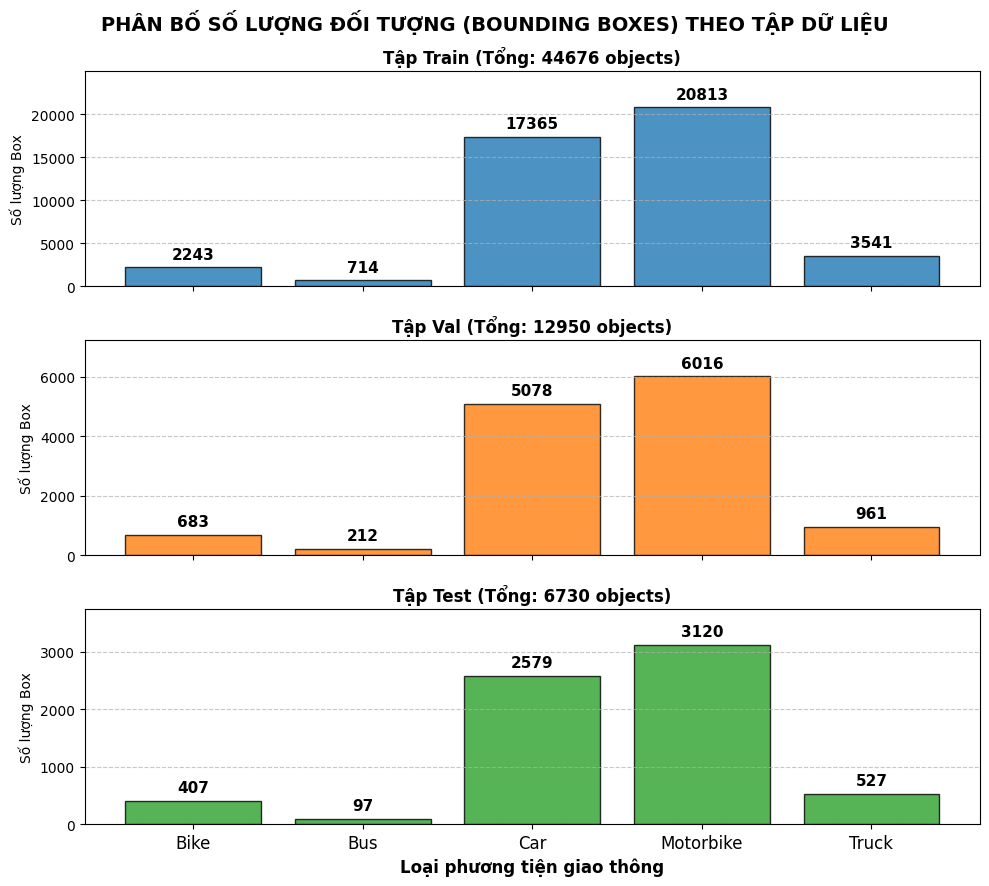


💾 Đã lưu biểu đồ phân bố tại: traffic_distribution.png


In [4]:
import os
import glob
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN VÀ CLASS
# ==========================================
# Trỏ đường dẫn đến thư mục chứa các file nhãn (.txt) của YOLO
LABELS_DIR = {
    'Train': r'D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\data\labels\train',
    'Val': r'D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\data\labels\val',   # Đã sửa thành 'val' theo chuẩn YOLO
    'Test': r'D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\data\labels\test'
}

CLASS_NAMES = ['Bike', 'Bus', 'Car', 'Motorbike', 'Truck']

# ==========================================
# 2. HÀM ĐẾM SỐ LƯỢNG BOUNDING BOX
# ==========================================
def count_bounding_boxes(label_dir):
    """Đọc toàn bộ file .txt trong thư mục và đếm số lượng từng class ID"""
    class_counts = Counter()
    
    if not os.path.exists(label_dir):
        print(f"⚠️ Cảnh báo: Không tìm thấy thư mục {label_dir}")
        return class_counts

    txt_files = glob.glob(os.path.join(label_dir, '*.txt'))
    
    for txt_file in txt_files:
        with open(txt_file, 'r') as f:
            lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) > 0:
                    class_id = int(parts[0]) # ID của class luôn nằm ở cột đầu tiên
                    class_counts[class_id] += 1
                    
    return class_counts

# ==========================================
# 3. TIẾN HÀNH THỐNG KÊ
# ==========================================
print("⏳ Đang quét và đếm số lượng Bounding Box...")
data_counts = {}
for split_name, path in LABELS_DIR.items():
    counts = count_bounding_boxes(path)
    # Map ID sang tên Class, nếu ID không có thì trả về 0
    data_counts[split_name] = [counts.get(i, 0) for i in range(len(CLASS_NAMES))]
    print(f"✅ {split_name}: Tìm thấy {sum(data_counts[split_name])} objects.")

# ==========================================
# 4. VẼ 3 BIỂU ĐỒ PHÂN BỐ (TRAIN - VAL - TEST)
# ==========================================
# Kéo dài chiều cao biểu đồ một chút (10, 9) để các biểu đồ không bị ép vào nhau
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Xanh dương, Cam, Xanh lá

plt.suptitle("PHÂN BỐ SỐ LƯỢNG ĐỐI TƯỢNG (BOUNDING BOXES) THEO TẬP DỮ LIỆU", fontsize=14, fontweight='bold', y=0.98)

for i, (split_name, counts) in enumerate(data_counts.items()):
    ax = axes[i]
    x_pos = np.arange(len(CLASS_NAMES))
    
    # Vẽ Bar chart
    bars = ax.bar(x_pos, counts, color=colors[i], edgecolor='black', alpha=0.8)
    
    max_val = max(counts) if sum(counts) > 0 else 10
    ax.set_ylim(0, max_val * 1.2) # Nới rộng trần biểu đồ để số liệu không chạm viền
    
    # Tiêu đề và nhãn
    ax.set_title(f'Tập {split_name} (Tổng: {sum(counts)} objects)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Số lượng Box', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Hiển thị số lượng trực tiếp trên từng cột
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f'{int(height)}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),  # offset lên 4 points
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=11, fontweight='bold')

# Cấu hình trục X cho toàn bộ biểu đồ (nằm ở biểu đồ dưới cùng)
axes[-1].set_xticks(x_pos)
axes[-1].set_xticklabels(CLASS_NAMES, fontsize=12)
axes[-1].set_xlabel('Loại phương tiện giao thông', fontsize=12, fontweight='bold')

plt.tight_layout()
# Nới khoảng cách giữa các đồ thị phụ
plt.subplots_adjust(hspace=0.25) 

save_path = 'traffic_distribution.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n💾 Đã lưu biểu đồ phân bố tại: {save_path}")

## ĐẾM ẢNH TỪNG TẬP

⏳ Đang quét dữ liệu từ các thư mục...

📊 BẢNG THỐNG KÊ SỐ LƯỢNG ẢNH THEO TỪNG TẬP DỮ LIỆU
Tập dữ liệu  Train  Valid  Test
Loại vũ khí                    
Grenade      13746   2963  2931
Handgun      13735   2972  3013
Rifle        13747   3654  3623
Steel arms   14277   3080  3077


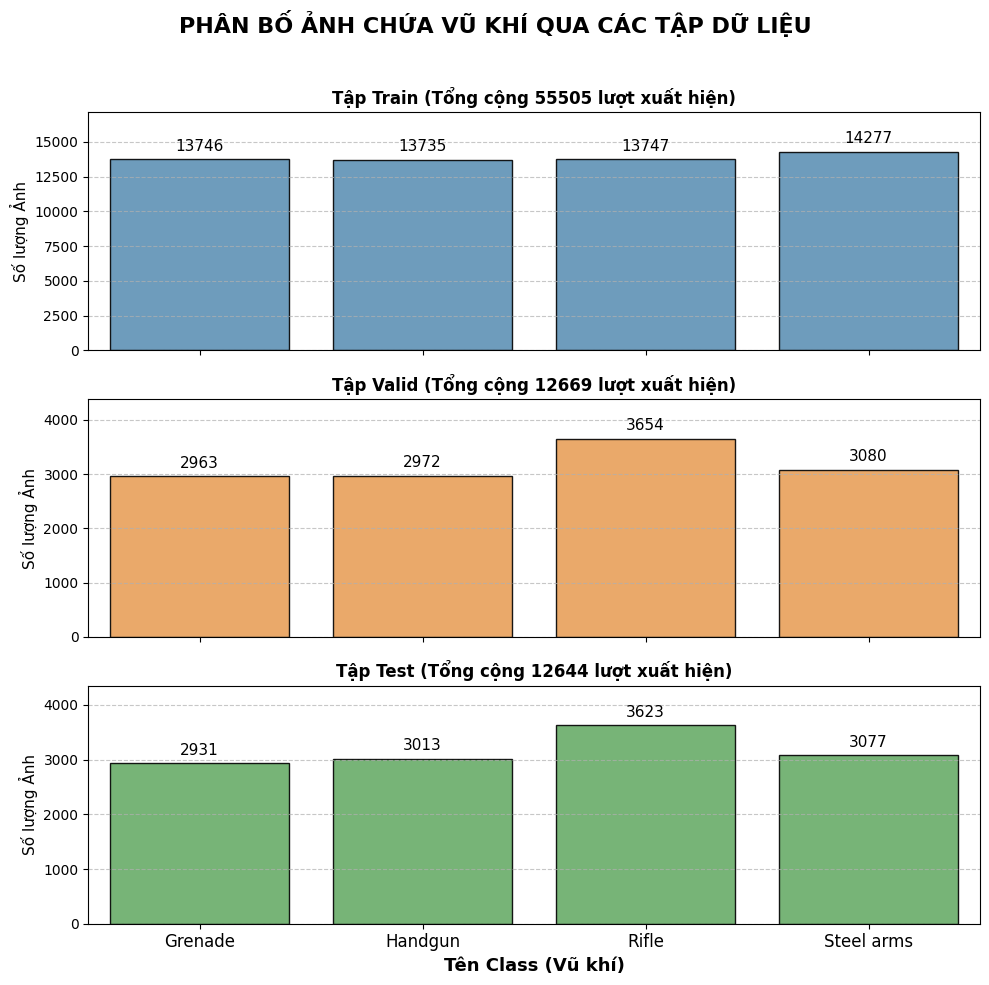

💾 Đã lưu biểu đồ phân bố ảnh tại: weapons_images_splits.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN VÀ TÊN LỚP
# ==========================================
BASE_DIR = r'D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau' 
FOLDERS = ['train', 'val', 'test'] 

# Danh sách 4 class vũ khí (Weapon Detection)
class_list = ['Grenade', 'Handgun', 'Rifle', 'Steel arms']
CLASS_NAMES = {i: name for i, name in enumerate(class_list)}

def analyze_weapon_data_splits(base_dir, folders):
    all_data = []
    
    print("⏳ Đang quét dữ liệu từ các thư mục...")
    
    # ==========================================
    # 2. QUÉT VÀ THỐNG KÊ THEO TỪNG THƯ MỤC
    # ==========================================
    for folder in folders:
        labels_path = os.path.join(base_dir, folder, 'labels')
        
        if not os.path.exists(labels_path):
            print(f"⚠️ Bỏ qua: Không tìm thấy {labels_path}")
            continue

        label_files = [f for f in os.listdir(labels_path) if f.endswith('.txt') and f != 'classes.txt']
        
        # Khởi tạo bộ đếm cho folder hiện tại (đảm bảo class 0 ảnh vẫn hiện)
        folder_counts = {name: 0 for name in class_list}
        total_images = len(label_files)
        
        for label_file in label_files:
            # DÙNG SET ĐỂ ĐẾM ẢNH (Mỗi class chỉ tính 1 lần dù có nhiều Bounding Box)
            classes_in_image = set() 
            with open(os.path.join(labels_path, label_file), 'r') as f:
                for line in f:
                    parts = line.split()
                    if parts:
                        class_id = int(parts[0])
                        classes_in_image.add(CLASS_NAMES.get(class_id, f"ID_{class_id}"))
            
            # Cộng dồn vào bộ đếm của thư mục
            for c_name in classes_in_image:
                if c_name in folder_counts:
                    folder_counts[c_name] += 1
                    
        # Đẩy dữ liệu vào mảng tổng
        split_name = folder.capitalize()
        if split_name == 'Val': split_name = 'Valid' # Đổi tên hiển thị cho đẹp
        
        for c_name, count in folder_counts.items():
            all_data.append({
                'Tập dữ liệu': split_name, 
                'Loại vũ khí': c_name, 
                'Số lượng Ảnh': count
            })

    # ==========================================
    # 3. TẠO DATAFRAME VÀ IN BÁO CÁO CONSOLE
    # ==========================================
    df = pd.DataFrame(all_data)
    
    # Tạo bảng Pivot để hiển thị ra màn hình dạng ma trận
    pivot_table = df.pivot(index='Loại vũ khí', columns='Tập dữ liệu', values='Số lượng Ảnh')
    # Sắp xếp cột theo thứ tự chuẩn
    cols_order = [col for col in ['Train', 'Valid', 'Test'] if col in pivot_table.columns]
    pivot_table = pivot_table[cols_order]
    
    print("\n" + "="*60)
    print("📊 BẢNG THỐNG KÊ SỐ LƯỢNG ẢNH THEO TỪNG TẬP DỮ LIỆU")
    print("="*60)
    print(pivot_table)
    print("="*60)

    # ==========================================
    # 4. VẼ BIỂU ĐỒ 3x1 (TRAIN - VALID - TEST)
    # ==========================================
    # Thiết lập layout 3 hàng 1 cột
    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    plt.suptitle("PHÂN BỐ ẢNH CHỨA VŨ KHÍ QUA CÁC TẬP DỮ LIỆU", fontsize=16, fontweight='bold', y=0.98)
    
    colors = {'Train': '#4f94c4', 'Valid': '#ff9f43', 'Test': '#5cb85c'}
    splits = [s for s in ['Train', 'Valid', 'Test'] if s in df['Tập dữ liệu'].unique()]

    for i, split in enumerate(splits):
        ax = axes[i]
        split_data = df[df['Tập dữ liệu'] == split]
        total_in_split = split_data['Số lượng Ảnh'].sum()
        
        # Vẽ cột
        sns.barplot(
            data=split_data, x='Loại vũ khí', y='Số lượng Ảnh', 
            ax=ax, color=colors[split], edgecolor='black', alpha=0.9
        )
        
        # Mở rộng trục Y thêm 20% để không bị lẹm chữ
        max_val = split_data['Số lượng Ảnh'].max()
        ax.set_ylim(0, max_val * 1.2 if max_val > 0 else 10)
        
        # Tiêu đề và nhãn
        ax.set_title(f'Tập {split} (Tổng cộng {total_in_split} lượt xuất hiện)', fontsize=12, fontweight='bold')
        ax.set_ylabel('Số lượng Ảnh', fontsize=11)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        
        # Ghi số liệu lên đỉnh cột
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                ax.annotate(f'{int(height)}',
                            xy=(p.get_x() + p.get_width() / 2, height),
                            xytext=(0, 4),  # Cách đỉnh 4 points
                            textcoords="offset points",
                            ha='center', va='bottom', fontsize=11)

    # Cấu hình trục X ở biểu đồ dưới cùng
    axes[-1].set_xlabel('Tên Class (Vũ khí)', fontsize=13, fontweight='bold')
    axes[-1].tick_params(axis='x', labelsize=12)

    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Chừa không gian cho Suptitle
    save_path = 'weapons_images_splits.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    import os
import glob
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN VÀ TÊN LỚP
# ==========================================
BASE_DIR = r'D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau' 
FOLDERS = ['train', 'val', 'test'] 

CLASS_NAMES = ['Grenade', 'Handgun', 'Rifle', 'Steel arms']

# ==========================================
# 2. HÀM ĐẾM SỐ LƯỢNG ẢNH (KHÔNG ĐẾM BOX)
# ==========================================
def count_images_per_class(label_dir):
    """
    Đếm số lượng ẢNH có chứa ít nhất 1 đối tượng của từng lớp.
    Dùng set() để đảm bảo dù có 10 khẩu súng trong 1 ảnh thì cũng chỉ tính là 1 ảnh có Handgun.
    """
    class_counts = {i: 0 for i in range(len(CLASS_NAMES))}
    
    if not os.path.exists(label_dir):
        print(f"⚠️ Cảnh báo: Không tìm thấy thư mục {label_dir}")
        return class_counts

    txt_files = glob.glob(os.path.join(label_dir, '*.txt'))
    
    for txt_file in txt_files:
        classes_in_image = set() # Tập hợp lưu ID các class có trong 1 bức ảnh
        
        with open(txt_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) > 0:
                    class_id = int(parts[0])
                    classes_in_image.add(class_id)
        
        # Cộng thêm 1 vào đếm ảnh cho mỗi class xuất hiện trong bức ảnh này
        for class_id in classes_in_image:
            if class_id in class_counts:
                class_counts[class_id] += 1
                
    return class_counts

# ==========================================
# 3. TIẾN HÀNH THỐNG KÊ CHO TỪNG TẬP
# ==========================================
print("⏳ Đang quét và đếm số lượng ẢNH cho từng tập...")
data_counts = {}

for split_name in FOLDERS:
    labels_path = os.path.join(BASE_DIR, split_name, 'labels')
    counts_dict = count_images_per_class(labels_path)
    
    # Chuyển đổi thành dạng mảng theo thứ tự CLASS_NAMES
    data_counts[split_name.capitalize()] = [counts_dict[i] for i in range(len(CLASS_NAMES))]
    
    print(f"✅ {split_name.capitalize()}: Hoàn tất quét thư mục.")

# ==========================================
# 4. VẼ BIỂU ĐỒ 3 TẦNG (FIX LỖI TRÀN CHỮ)
# ==========================================
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
colors = ['#4f94c4', '#ff9f43', '#5cb85c'] # Xanh lam (Train), Cam (Val), Xanh lá (Test)

for i, (split_name, counts) in enumerate(data_counts.items()):
    ax = axes[i]
    x_pos = np.arange(len(CLASS_NAMES))
    
    # Vẽ Bar chart
    bars = ax.bar(x_pos, counts, color=colors[i], edgecolor='black', alpha=0.9)
    
    # Mở rộng giới hạn trục Y thêm 15% để tránh lẹm số trên đỉnh cột
    max_val = max(counts) if sum(counts) > 0 else 10
    ax.set_ylim(0, max_val * 1.15) 
    
    # Tiêu đề và nhãn trục
    ax.set_title(f'Số lượng ẢNH chứa từng loại vũ khí - Tập {split_name}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Số lượng Ảnh', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Hiển thị số lượng trực tiếp trên từng cột
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f'{int(height)}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),  # Cách đỉnh cột 4 pixel
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=10)

# Cấu hình trục X
axes[-1].set_xticks(x_pos)
axes[-1].set_xticklabels(CLASS_NAMES, fontsize=11)
axes[-1].set_xlabel('Tên Class (Vũ khí)', fontsize=12, fontweight='bold')

plt.tight_layout()
save_path = 'weapons_images_distribution_split.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n💾 Đã lưu biểu đồ phân bố ẢNH tại: {save_path}")
    print(f"💾 Đã lưu biểu đồ phân bố ảnh tại: {save_path}")
    return df

stats_df = analyze_weapon_data_splits(BASE_DIR, FOLDERS)

## ĐẾM ẢNH TỔNG

⏳ Đang quét dữ liệu từ các thư mục...

📊 THỐNG KÊ PHÂN BỐ ẢNH WEAPON (TỔNG HỢP 3 TẬP)
Tổng số file txt (ảnh) đã quét: 31486
   Tên lớp  Số lượng Ảnh  Tỷ lệ (%)
     Rifle         21024      26.01
Steel arms         20434      25.28
   Handgun         19720      24.40
   Grenade         19640      24.30


C:\Users\K0HEI\AppData\Local\Temp\ipykernel_12336\878147318.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats, y='Tên lớp', x='Số lượng Ảnh', palette='magma', ax=ax1)


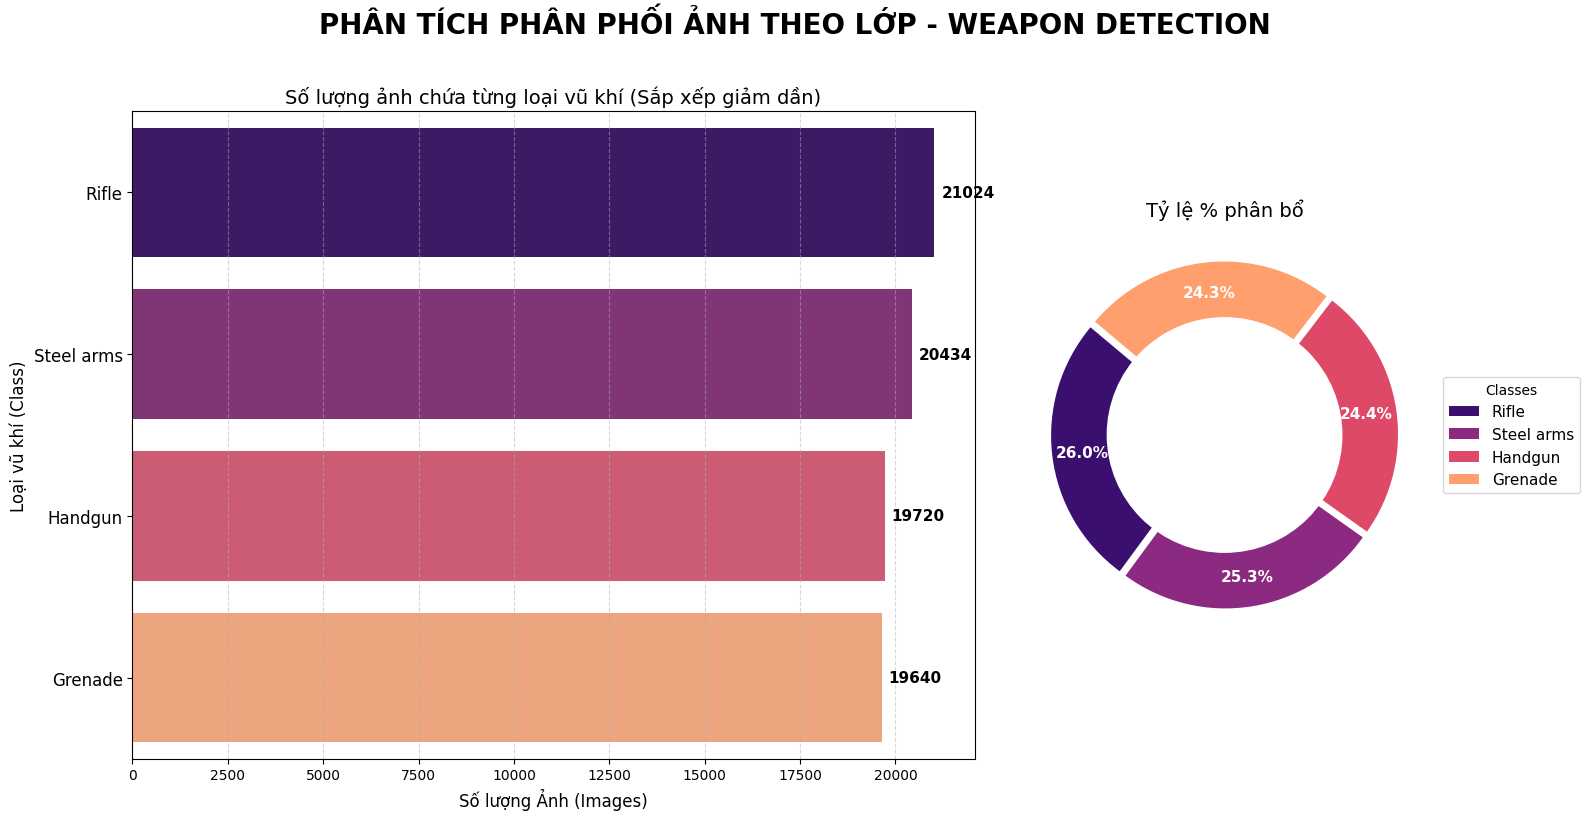

In [29]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN VÀ TÊN LỚP
# ==========================================
# Đổi lại đường dẫn đích mà bạn vừa gộp xong ở bước trước
BASE_DIR = r'D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau' 
FOLDERS = ['train', 'val', 'test'] 

# Danh sách 4 class vũ khí (Weapon Detection)
class_list = ['Grenade', 'Handgun', 'Rifle', 'Steel arms']
# Map index sang tên class (0 -> Grenade, 1 -> Handgun, ...)
CLASS_NAMES = {i: name for i, name in enumerate(class_list)}

def analyze_weapon_data(base_dir, folders):
    class_counts = []
    total_images_scanned = 0
    
    print("⏳ Đang quét dữ liệu từ các thư mục...")
    
    # Duyệt qua cả 3 thư mục
    for folder in folders:
        labels_path = os.path.join(base_dir, folder, 'labels')
        
        if not os.path.exists(labels_path):
            print(f"⚠️ Bỏ qua: Không tìm thấy {labels_path}")
            continue

        label_files = [f for f in os.listdir(labels_path) if f.endswith('.txt') and f != 'classes.txt']
        total_images_scanned += len(label_files)
        
        for label_file in label_files:
            # DÙNG SET ĐỂ ĐẾM ẢNH (Không đếm Bounding Box)
            classes_in_image = set() 
            with open(os.path.join(labels_path, label_file), 'r') as f:
                for line in f:
                    parts = line.split()
                    if parts:
                        class_id = int(parts[0])
                        classes_in_image.add(CLASS_NAMES.get(class_id, f"ID_{class_id}"))
            
            # Đưa các class xuất hiện trong ảnh này vào mảng đếm
            class_counts.extend(list(classes_in_image))

    # ==========================================
    # 2. TẠO DATAFRAME THỐNG KÊ
    # ==========================================
    df = pd.DataFrame(class_counts, columns=['Tên lớp'])
    stats = df['Tên lớp'].value_counts().reset_index()
    stats.columns = ['Tên lớp', 'Số lượng Ảnh']
    
    # Đảm bảo hiển thị đủ 4 lớp (Kể cả lớp có 0 ảnh)
    all_classes_df = pd.DataFrame({'Tên lớp': class_list})
    stats = pd.merge(all_classes_df, stats, on='Tên lớp', how='left').fillna(0)
    stats['Số lượng Ảnh'] = stats['Số lượng Ảnh'].astype(int)
    
    # Sắp xếp giảm dần để biểu đồ cột trông chuyên nghiệp
    stats = stats.sort_values(by='Số lượng Ảnh', ascending=False)
    
    total_instances = stats['Số lượng Ảnh'].sum()
    stats['Tỷ lệ (%)'] = (stats['Số lượng Ảnh'] / total_instances * 100).round(2)
    
    # Hiển thị console
    print("\n" + "="*55)
    print(f"📊 THỐNG KÊ PHÂN BỐ ẢNH WEAPON (TỔNG HỢP {len(folders)} TẬP)")
    print(f"Tổng số file txt (ảnh) đã quét: {total_images_scanned}")
    print("="*55)
    print(stats.to_string(index=False))
    print("="*55)

    # ==========================================
    # 3. VẼ BIỂU ĐỒ 
    # ==========================================
    # Thu gọn kích thước (16x8) để phù hợp với 4 class
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [2, 1]})
    plt.suptitle("PHÂN TÍCH PHÂN PHỐI ẢNH THEO LỚP - WEAPON DETECTION", fontsize=20, fontweight='bold', y=1.02)

    # Biểu đồ 1: Cột ngang (Barplot)
    sns.barplot(data=stats, y='Tên lớp', x='Số lượng Ảnh', palette='magma', ax=ax1)
    
    # Thêm số lượng trực tiếp lên đuôi mỗi cột
    for i in ax1.containers:
        ax1.bar_label(i, padding=5, fontsize=11, fontweight='bold')
        
    ax1.set_title("Số lượng ảnh chứa từng loại vũ khí (Sắp xếp giảm dần)", fontsize=14)
    ax1.set_xlabel("Số lượng Ảnh (Images)", fontsize=12)
    ax1.set_ylabel("Loại vũ khí (Class)", fontsize=12)
    ax1.grid(axis='x', linestyle='--', alpha=0.5)
    ax1.tick_params(axis='y', labelsize=12)

    # Biểu đồ 2: Donut Chart - Tỷ lệ phần trăm
    colors = sns.color_palette('magma', len(stats))
    
    wedges, texts, autotexts = ax2.pie(
        stats['Số lượng Ảnh'], 
        autopct='%1.1f%%', # Luôn hiển thị % vì chỉ có 4 class
        startangle=140, 
        colors=colors, 
        pctdistance=0.82,
        explode=[0.03] * len(stats) # Tách nứt nhẹ
    )
    
    # Làm đẹp font chữ bên trong Donut
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_fontsize(11)
        autotext.set_fontweight('bold')

    # Vòng tròn trắng ở giữa
    centre_circle = plt.Circle((0,0), 0.70, fc='white')
    ax2.add_artist(centre_circle)
    ax2.set_title("Tỷ lệ % phân bổ", fontsize=14)
    
    # Thêm Legend ở ngoài 
    ax2.legend(wedges, stats['Tên lớp'], title="Classes", loc="center left", bbox_to_anchor=(1, 0.5), fontsize=11)

    plt.tight_layout()
    plt.show()

    return stats

# Chạy script
stats_result = analyze_weapon_data(BASE_DIR, FOLDERS)

## KIỂM TRA 3 MẪU

CELL 6: VISUALIZE DATASET

📸 Hiển thị 3 mẫu ngẫu nhiên...


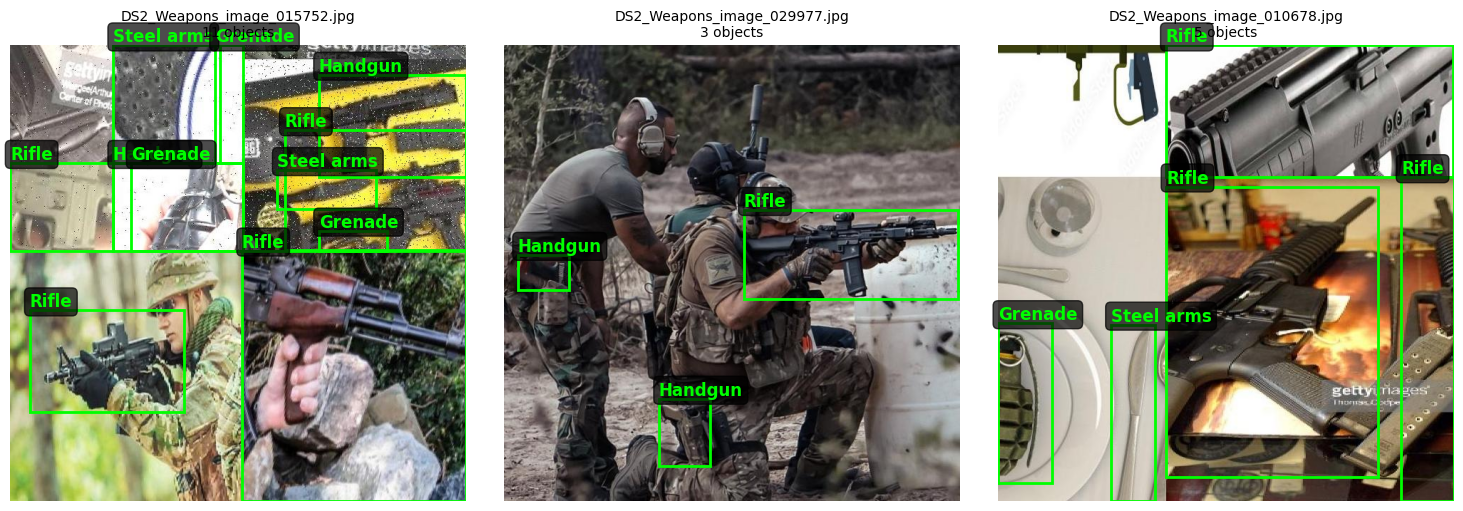


✅ Đã lưu preview: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\dataset_preview.jpg


In [75]:
# =============================================================================
# CELL 6: VISUALIZE DATASET
# =============================================================================

print("="*80)
print("CELL 6: VISUALIZE DATASET")
print("="*80)

print("\n📸 Hiển thị 3 mẫu ngẫu nhiên...")

train_images_dir = os.path.join(OUTPUT_DATASET_PATH, 'train', 'images')
train_labels_dir = os.path.join(OUTPUT_DATASET_PATH, 'train', 'labels')

if os.path.exists(train_images_dir):
    all_imgs = [f for f in os.listdir(train_images_dir) if f.endswith(('.jpg', '.png'))]
    if len(all_imgs) >= 3:
        sample_imgs = random.sample(all_imgs, 3)
        
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        for i, img_name in enumerate(sample_imgs):
            img_path = os.path.join(train_images_dir, img_name)
            label_name = os.path.splitext(img_name)[0] + '.txt'
            label_path = os.path.join(train_labels_dir, label_name)
            
            img = np.array(Image.open(img_path))
            h, w = img.shape[:2]
            
            ax = axes[i]
            ax.imshow(img)
            ax.axis('off')
            
            n_boxes = 0
            if os.path.exists(label_path):
                with open(label_path, 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            class_id = int(parts[0])
                            x_center, y_center, width, height = map(float, parts[1:5])
                            
                            x1 = int((x_center - width/2) * w)
                            y1 = int((y_center - height/2) * h)
                            box_w = int(width * w)
                            box_h = int(height * h)
                            
                            rect = patches.Rectangle((x1, y1), box_w, box_h, 
                                                   linewidth=2, edgecolor='lime', facecolor='none')
                            ax.add_patch(rect)
                            ax.text(x1, y1-5, f'{MANUAL_CLASS_NAMES[class_id]}', 
                                    color='lime', fontsize=12, weight='bold',
                                    bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))
                            n_boxes += 1
            
            ax.set_title(f'{img_name}\n{n_boxes} objects', fontsize=10)
            
        plt.tight_layout()
        preview_path = os.path.join(OUTPUT_DATASET_PATH, 'dataset_preview.jpg')
        plt.savefig(preview_path, dpi=150, bbox_inches='tight')
        plt.show()
        
        print(f"\n✅ Đã lưu preview: {preview_path}")

# DEFAULT

## TRAIN MÔ HÌNH

In [ ]:
import os
import shutil
from ultralytics import YOLO

# =============================================================================
# KHỞI TẠO VÀ KIỂM TRA ĐẦU VÀO
# =============================================================================

# Đường dẫn file cấu hình dữ liệu (.yaml)
yaml_path = os.path.join(OUTPUT_DATASET_PATH, 'data.yaml')

# Dừng chương trình chờ người dùng kiểm tra thông số trước khi chạy
input("⏸️ Nhấn ENTER để bắt đầu...")

# In ra các thông số thiết lập hiện tại
print(f"Model: {MODEL_NAME}") # Tên model sử dụng (ví dụ: yolov11n.pt)
print(f"Epochs: {EPOCHS}")     # Số lượt huấn luyện = 100
print(f"Batch: {BATCH_SIZE}")  # Số ảnh xử lý cùng lúc (ví dụ: 16)
print(f"Device: {DEVICE}")     # '0' = GPU, 'cpu' = CPU

# =============================================================================
# QUÁ TRÌNH HUẤN LUYỆN (TRAINING)
# =============================================================================

# Tải cấu trúc model YOLO
model = YOLO(MODEL_NAME)

# Bắt đầu quá trình học từ dữ liệu
results = model.train(
    data=yaml_path,     # Đường dẫn file yaml chứa danh mục ảnh
    epochs=EPOCHS,       # Số vòng lặp huấn luyện
    imgsz=IMG_SIZE,     # Kích thước ảnh đầu vào (ví dụ: 640)
    batch=BATCH_SIZE,   # Số lượng ảnh mỗi bước cập nhật trọng số
    device=DEVICE,       # '0' = GPU, 'cpu' = CPU
    project=PROJECT_NAME, # Tên thư mục tổng quản lý các lần chạy
    name=EXPERIMENT_NAME  # Tên thư mục riêng cho lần chạy này
)

# =============================================================================
# XỬ LÝ KẾT QUẢ SAU KHI TRAIN
# =============================================================================

# Xác định vị trí các file kết quả vừa sinh ra
training_dir = os.path.join(PROJECT_NAME, EXPERIMENT_NAME) # Thư mục chứa kết quả
best_model_path = os.path.join(training_dir, 'weights', 'best.pt') # Model có độ chính xác cao nhất
last_model_path = os.path.join(training_dir, 'weights', 'last.pt') # Model ở vòng lặp cuối cùng

# Tạo thư mục lưu trữ vĩnh viễn (Output)
output_save_dir = os.path.join(OUTPUT_DATASET_PATH, 'trained_models')
os.makedirs(output_save_dir, exist_ok=True) # Tạo folder nếu chưa có

# Sao chép file model tốt nhất vào thư mục lưu trữ
if os.path.exists(best_model_path):
    dest = os.path.join(output_save_dir, 'best.pt')
    shutil.copy2(best_model_path, dest) # Copy file kèm theo thông tin thời gian (metadata)

# Sao chép toàn bộ nhật ký (Logs, biểu đồ, ảnh kết quả)
dest_logs = os.path.join(output_save_dir, 'training_logs')
if os.path.exists(training_dir):
    if os.path.exists(dest_logs):
        shutil.rmtree(dest_logs) # Xóa log cũ nếu đã tồn tại để ghi đè
    shutil.copytree(training_dir, dest_logs) # Copy nguyên cây thư mục kết quả

print("🎉 TẤT CẢ ĐÃ ĐƯỢC LƯU VÀO OUTPUT!") # Thông báo hoàn tất

CELL 7: TRAINING YOLOV11n (DEFAULT SETTINGS)

🚀 Bắt đầu training...
   Model: yolo11n.pt
   Epochs: 100
   Batch: 8
   Device: 0

New https://pypi.org/project/ultralytics/8.4.39 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.241  Python-3.10.0 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0

## ĐÁNH GIÁ CHỈ SỐ 

In [22]:
import pandas as pd
import os

# Cấu hình đường dẫn tới thư mục logs đã lưu ở Cell 7
LOGS_DIR = os.path.join(ORIGINAL_DATASET_PATH, 'runs', 'train', 'yolo26_traffic')
csv_path = os.path.join(LOGS_DIR, 'results.csv')

if os.path.exists(csv_path):
    # Đọc file kết quả
    df = pd.read_csv(csv_path)
    
    # Xóa khoảng trắng thừa trong tên cột của YOLO
    df.columns = df.columns.str.strip() 
    
    # 🌟 THAY ĐỔI CỐT LÕI TẠI ĐÂY 🌟
    # Tính điểm Fitness theo đúng công thức nội bộ của YOLOv8
    fitness_scores = 0.1 * df['metrics/mAP50(B)'] + 0.9 * df['metrics/mAP50-95(B)']
    
    # Tìm ra vị trí (index) của epoch có điểm Fitness cao nhất
    best_epoch_idx = fitness_scores.idxmax()
    best_epoch_data = df.iloc[best_epoch_idx]
    
    print("="*65)
    print("🎯 TỔNG KẾT CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH (BEST EPOCH)")
    print("="*65)
    
    # Cộng 1 vào epoch vì index của Python bắt đầu từ 0, nhưng epoch tính từ 1
    print(f"🌟 Epoch đạt đỉnh (Best) : {int(best_epoch_data['epoch'])}") 
    print(f"🔹 Precision (Độ chuẩn xác) : {best_epoch_data['metrics/precision(B)']:.4f}")
    print(f"🔹 Recall (Độ phủ)          : {best_epoch_data['metrics/recall(B)']:.4f}")
    print(f"🔹 mAP@50                   : {best_epoch_data['metrics/mAP50(B)']:.4f}")
    print(f"🔹 mAP@50-95 (Khắt khe nhất): {best_epoch_data['metrics/mAP50-95(B)']:.4f}")
    
    # Tính F1-Score từ Precision và Recall của Epoch tốt nhất
    p = best_epoch_data['metrics/precision(B)']
    r = best_epoch_data['metrics/recall(B)']
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0
    print(f"🔹 F1-Score                 : {f1:.4f}")
    print("="*65)
else:
    print(f"❌ Không tìm thấy file {csv_path}. Bạn đã chạy xong bước Training chưa?")

🎯 TỔNG KẾT CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH (BEST EPOCH)
🌟 Epoch đạt đỉnh (Best) : 250
🔹 Precision (Độ chuẩn xác) : 0.9237
🔹 Recall (Độ phủ)          : 0.8925
🔹 mAP@50                   : 0.9457
🔹 mAP@50-95 (Khắt khe nhất): 0.7741
🔹 F1-Score                 : 0.9078



📊 Đang vẽ biểu đồ 4 chỉ số tổng quan...


C:\Users\K0HEI\AppData\Local\Temp\ipykernel_16504\1949269028.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=metrics_names, y=metrics_values, palette=palette, edgecolor='black', linewidth=1.5)


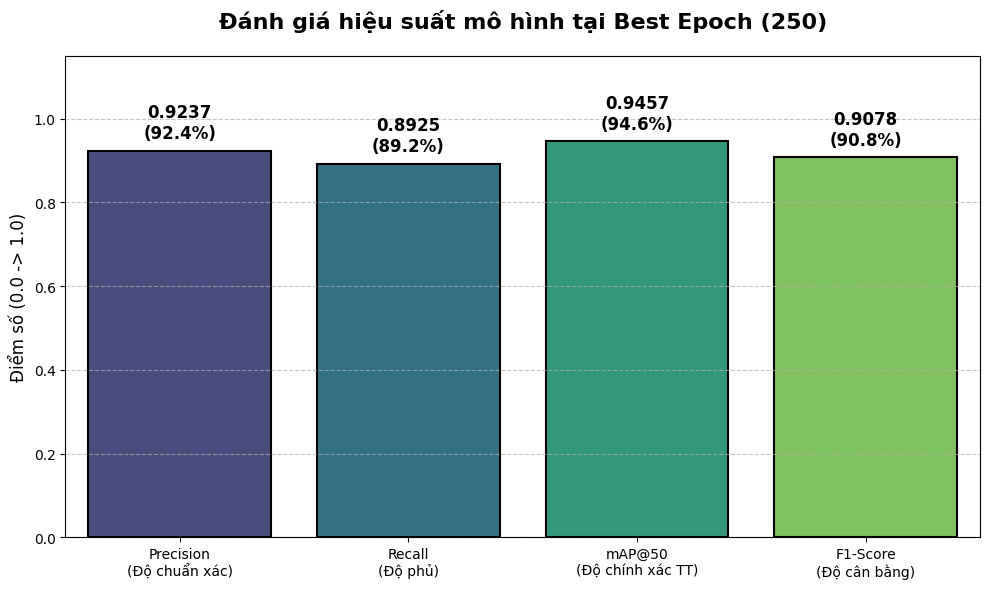

💾 Đã lưu biểu đồ 4 chỉ số tại: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic\best_epoch_4_metrics.png


In [23]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# ĐỌC LOGS VÀ TÌM BEST EPOCH
# ==========================================
LOGS_DIR = r'D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic' 
csv_path = os.path.join(LOGS_DIR, 'results.csv')

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip() 
    
    fitness_scores = 0.1 * df['metrics/mAP50(B)'] + 0.9 * df['metrics/mAP50-95(B)']
    best_epoch_idx = fitness_scores.idxmax()
    best_epoch_data = df.iloc[best_epoch_idx]
    
    # Trích xuất 4 chỉ số cốt lõi
    p = best_epoch_data['metrics/precision(B)']
    r = best_epoch_data['metrics/recall(B)']
    map50 = best_epoch_data['metrics/mAP50(B)']
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0

    # ==========================================
    # VẼ BIỂU ĐỒ 4 CHỈ SỐ (PRECISION, RECALL, mAP, F1)
    # ==========================================
    print("\n📊 Đang vẽ biểu đồ 4 chỉ số tổng quan...")
    
    # Chuẩn bị dữ liệu
    metrics_names = ['Precision\n(Độ chuẩn xác)', 'Recall\n(Độ phủ)', 'mAP@50\n(Độ chính xác TT)', 'F1-Score\n(Độ cân bằng)']
    metrics_values = [p, r, map50, f1]
    
    # Khởi tạo khung biểu đồ
    plt.figure(figsize=(10, 6))
    
    # Thiết lập bảng màu đẹp mắt (viridis, magma, hoặc pastel)
    palette = sns.color_palette("viridis", 4)
    
    # Vẽ biểu đồ cột
    ax = sns.barplot(x=metrics_names, y=metrics_values, palette=palette, edgecolor='black', linewidth=1.5)
    
    # Mở rộng trục Y lên 1.15 để không bị lẹm chữ (vì giá trị max là 1.0)
    ax.set_ylim(0, 1.15)
    
    # Tiêu đề và nhãn
    plt.title(f'Đánh giá hiệu suất mô hình tại Best Epoch ({int(best_epoch_data["epoch"])})', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('Điểm số (0.0 -> 1.0)', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Gắn Label số liệu trực tiếp lên đỉnh các cột (Hiển thị % cho dễ nhìn)
    for i, v in enumerate(metrics_values):
        ax.text(i, v + 0.02, f"{v:.4f}\n({v*100:.1f}%)", 
                ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

    plt.tight_layout()
    
    # Lưu ảnh
    save_bar_path = os.path.join(LOGS_DIR, 'best_epoch_4_metrics.png')
    plt.savefig(save_bar_path, dpi=300)
    plt.show()
    
    print(f"💾 Đã lưu biểu đồ 4 chỉ số tại: {save_bar_path}")

else:
    print("❌ Không tìm thấy file csv.")

## BIỂU ĐỒ LOSS - ACCURACY


📂 Đường dẫn đích: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic

💾 Đã lưu biểu đồ thành công tại: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic\box_loss.png


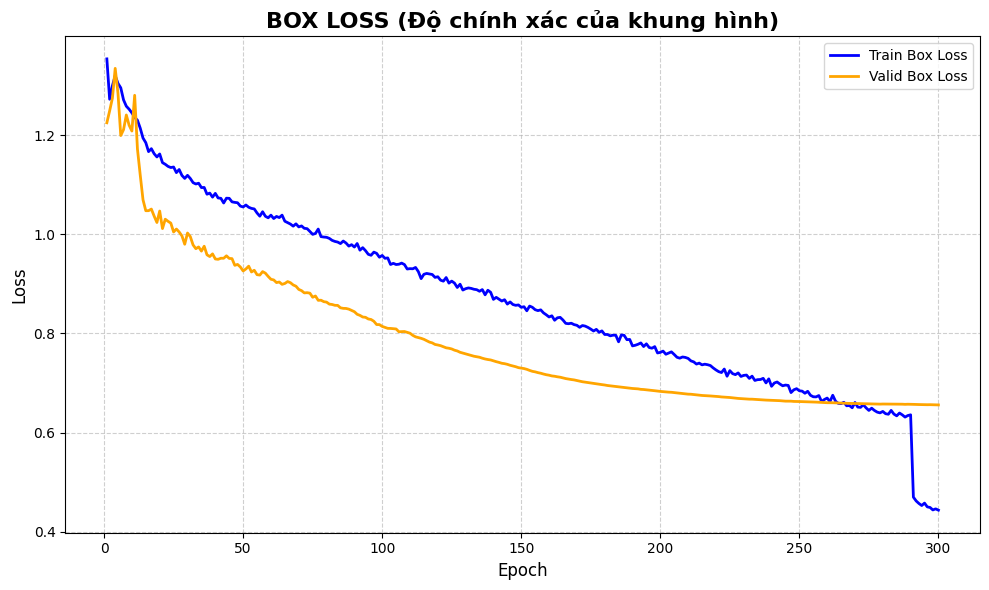

In [24]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN CHÍNH XÁC
# ==========================================
# Chuyển hướng chính xác về thư mục chứa dữ liệu đã train của bạn
output_save_dir = r"D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic"
os.makedirs(output_save_dir, exist_ok=True)
print(f"\n📂 Đường dẫn đích: {output_save_dir}\n")

# Đường dẫn tới file kết quả kết xuất từ YOLO
csv_path = os.path.join(output_save_dir, 'results.csv')

if os.path.exists(csv_path):
    # Đọc dữ liệu và xóa khoảng trắng thừa ở tên cột
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip() 

    # Khởi tạo khung vẽ biểu đồ Box Loss
    plt.figure(figsize=(10, 6))
    plt.plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', color='blue', linewidth=2)
    plt.plot(df['epoch'], df['val/box_loss'], label='Valid Box Loss', color='orange', linewidth=2)
    
    plt.title('BOX LOSS (Độ chính xác của khung hình)', fontsize=16, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    
    # --- ĐÃ SỬA: ĐƯA LOGIC LƯU VÀO TRONG IF VÀ ĐẶT TRƯỚC SHOW ---
    save_bar_path = os.path.join(output_save_dir, 'box_loss.png')
    plt.savefig(save_bar_path, dpi=300)
    print(f"💾 Đã lưu biểu đồ thành công tại: {save_bar_path}")
    
    # Hiển thị biểu đồ lên màn hình (Gọi sau cùng để tránh xóa bộ nhớ đệm)
    plt.show()
    
else:
    print(f"❌ Không tìm thấy file {csv_path}. Bạn kiểm tra lại tiến trình train nhé!")

💾 Đã lưu biểu đồ thành công tại: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic\cls_loss.png


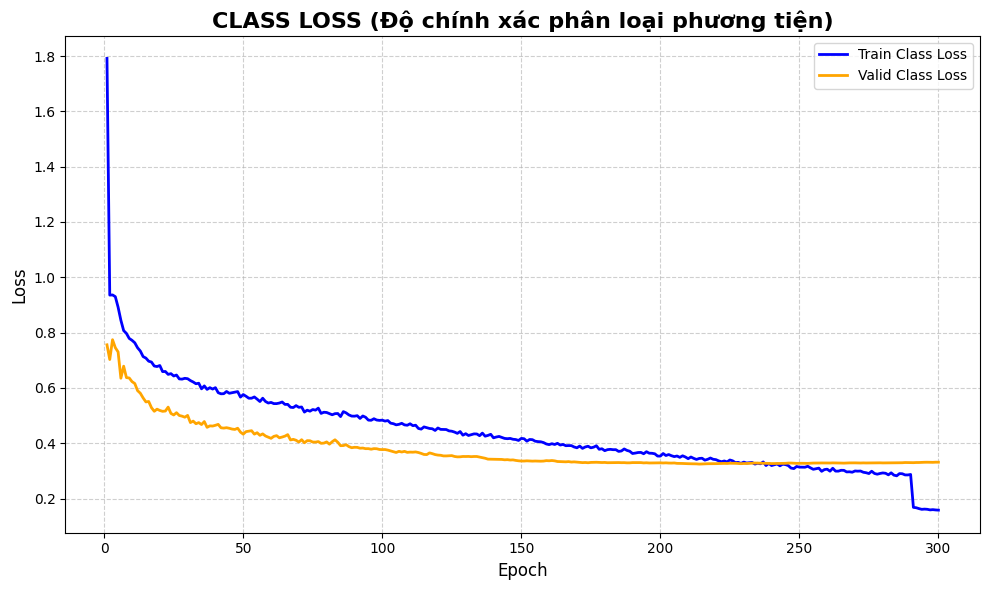

In [25]:
import os
import matplotlib.pyplot as plt

if 'df' in locals():
    # Đảm bảo đường dẫn lưu luôn tồn tại dù chạy ở cell nào
    output_save_dir = r"D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic"
    os.makedirs(output_save_dir, exist_ok=True)

    plt.figure(figsize=(10, 6))
    
    # Vẽ biểu đồ Class Loss
    plt.plot(df['epoch'], df['train/cls_loss'], label='Train Class Loss', color='blue', linewidth=2)
    plt.plot(df['epoch'], df['val/cls_loss'], label='Valid Class Loss', color='orange', linewidth=2)
    
    # --- ĐÃ SỬA: Đổi "vũ khí" thành "phương tiện" ---
    plt.title('CLASS LOSS (Độ chính xác phân loại phương tiện)', fontsize=16, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    
    # --- ĐÃ SỬA: Thêm logic lưu file ngay trước plt.show() ---
    save_cls_path = os.path.join(output_save_dir, 'cls_loss.png')
    plt.savefig(save_cls_path, dpi=300)
    print(f"💾 Đã lưu biểu đồ thành công tại: {save_cls_path}")
    
    # Hiển thị biểu đồ ra Output của Cell
    plt.show()
else:
    print("❌ Chưa có dữ liệu. Vui lòng chạy Cell 1 trước để nạp file CSV!")

💾 Đã lưu biểu đồ thành công tại: D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic\map_metrics.png


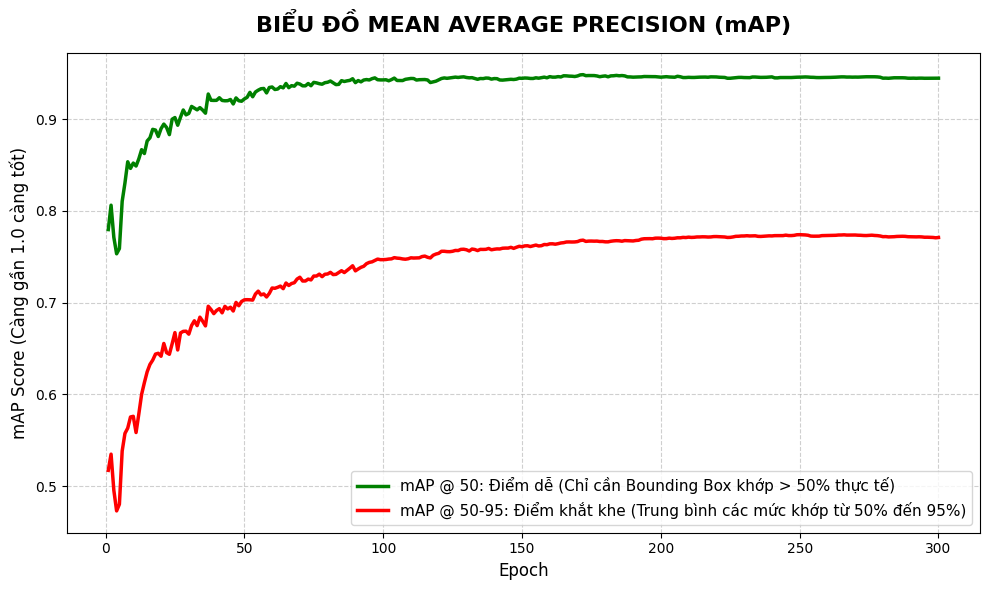

In [26]:
import os
import matplotlib.pyplot as plt

if 'df' in locals():
    # 1. Khai báo đường dẫn lưu ảnh (Đảm bảo đồng nhất thư mục)
    output_save_dir = r"D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\runs\train\yolo26_traffic"
    os.makedirs(output_save_dir, exist_ok=True)

    # 2. Khởi tạo và vẽ biểu đồ mAP
    plt.figure(figsize=(10, 6))
    
    # Định nghĩa chú thích rõ ràng bản chất của 2 đường
    label_map50 = 'mAP @ 50: Điểm dễ (Chỉ cần Bounding Box khớp > 50% thực tế)'
    label_map50_95 = 'mAP @ 50-95: Điểm khắt khe (Trung bình các mức khớp từ 50% đến 95%)'

    plt.plot(df['epoch'], df['metrics/mAP50(B)'], label=label_map50, color='green', linewidth=2.5)
    plt.plot(df['epoch'], df['metrics/mAP50-95(B)'], label=label_map50_95, color='red', linewidth=2.5)
    
    plt.title('BIỂU ĐỒ MEAN AVERAGE PRECISION (mAP)', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('mAP Score (Càng gần 1.0 càng tốt)', fontsize=12)
    
    # Kéo Legend xuống góc phải dưới để không đè lên đường đồ thị đang đi lên
    plt.legend(fontsize=11, loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    
    # --- BỔ SUNG: Logic lưu ảnh siêu nét trước khi show ---
    save_map_path = os.path.join(output_save_dir, 'map_metrics.png')
    plt.savefig(save_map_path, dpi=300)
    print(f"💾 Đã lưu biểu đồ thành công tại: {save_map_path}")
    
    # 3. Hiển thị biểu đồ
    plt.show()
else:
    print("❌ Lỗi: Chưa có dữ liệu. Bạn hãy chạy Cell 1 trước nhé!")

## CONFUSION MATRIX

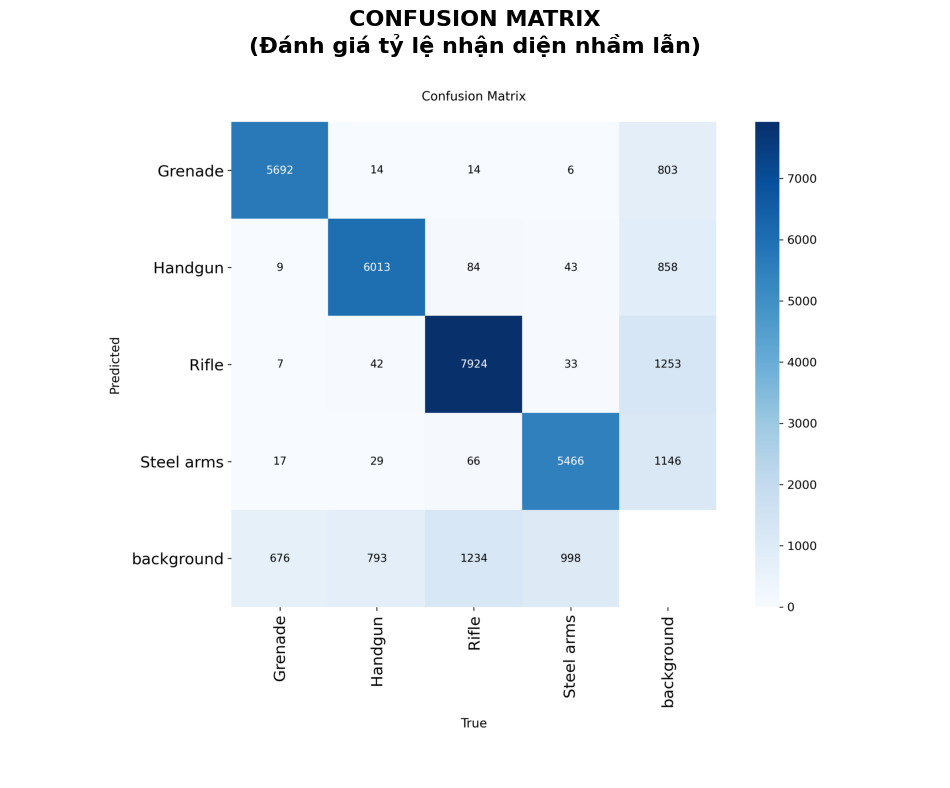

In [95]:
import cv2
import matplotlib.pyplot as plt
import os

cm_path = os.path.join(output_save_dir, 'training_logs', 'confusion_matrix.png')

if os.path.exists(cm_path):
    # Đọc ảnh bằng OpenCV và chuyển hệ màu BGR -> RGB
    img_cm = cv2.imread(cm_path)
    img_cm = cv2.cvtColor(img_cm, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 10))
    plt.imshow(img_cm)
    plt.axis('off') # Tắt trục tọa độ cho đẹp
    plt.title('CONFUSION MATRIX\n(Đánh giá tỷ lệ nhận diện nhầm lẫn)', fontsize=16, fontweight='bold', pad=20)
    plt.show()
else:
    print(f"❌ Không tìm thấy file {cm_path}.")

## PR CURVE

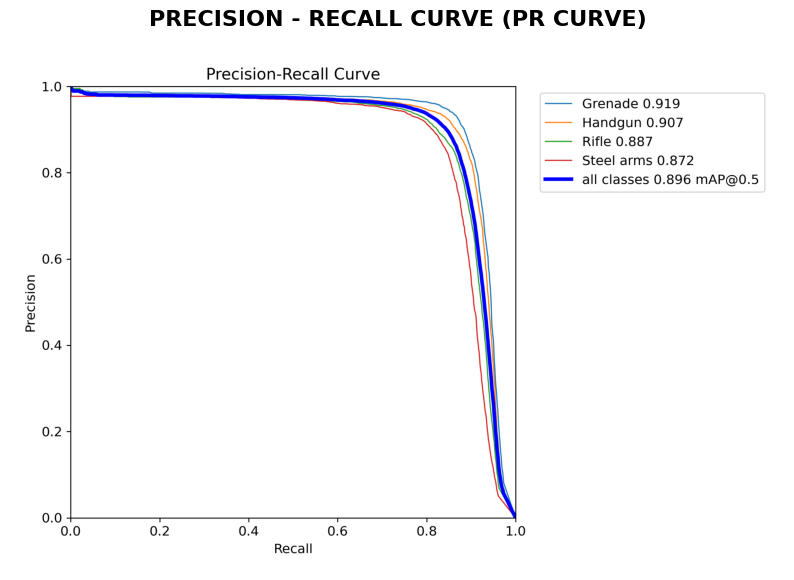

In [99]:
import cv2
import matplotlib.pyplot as plt
import os

# Đổi tên file thành 'BoxPR_curve.png' cho chuẩn với các bản Ultralytics mới
pr_path = os.path.join(output_save_dir, 'training_logs', 'BoxPR_curve.png')

if os.path.exists(pr_path):
    img_pr = cv2.imread(pr_path)
    img_pr = cv2.cvtColor(img_pr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 8))
    plt.imshow(img_pr)
    plt.axis('off')
    plt.title('PRECISION - RECALL CURVE (PR CURVE)', fontsize=16, fontweight='bold', pad=20)
    plt.show()
else:
    print(f"❌ Không tìm thấy file {pr_path}. Hãy kiểm tra lại thư mục logs!")

# OPTIMIZED

## TRAIN MÔ HÌNH

In [ ]:
import os
import shutil
from ultralytics import YOLO

# =============================================================================
# CELL 7: HIGH-PRECISION OPTIMIZATION FOR WEAPON CLASSIFICATION
# =============================================================================

print("="*80)
print("FOCUS: INCREASING PRECISION > 0.9138")
print("STRATEGIES: 4.1 (Weight Decay) | 4.2 (Dropout) | 7.1 (Head Gain)")
print("="*80)

yaml_path = os.path.join(OUTPUT_DATASET_PATH, 'data.yaml')
EXPERIMENT_NAME_HIGH_P = f"{EXPERIMENT_NAME}_high_precision"

# --- 1. KHỞI TẠO MODEL ---
# Full Fine-tuning (Nhóm 1.1) - Không freeze để mô hình tự do điều chỉnh toàn bộ tham số

model_opt = YOLO(MODEL_NAME)

print(f"\n🚀 Khởi động tiến trình tối ưu Precision...")

# --- 2. TRAINING CONFIGURATION ---
results_opt = model_opt.train(
    data=yaml_path,      # Đường dẫn tới file config dữ liệu (chứa path ảnh và tên class)
    epochs=EPOCHS,       # Tổng số lượt học toàn bộ tập dữ liệu
    imgsz=IMG_SIZE,      # Kích thước ảnh đầu vào (ví dụ: 640 là ảnh 640x640)
    batch=BATCH_SIZE,    # Số lượng ảnh xử lý cùng lúc trong mỗi bước tối ưu
    device=DEVICE,       # Thiết bị tính toán: '0' = GPU, 'cpu' = CPU
    project=PROJECT_NAME,# Tên thư mục cha để lưu các dự án huấn luyện
    name=EXPERIMENT_NAME_HIGH_P, # Tên thư mục con chứa kết quả của lần chạy này

    # 🌟 CHIẾN LƯỢC 4.1 & 4.2: Tăng Weight Decay và Dropout
    # Định nghĩa: Là một kỹ thuật thêm một "khoản phạt" vào hàm mất mát dựa trên độ lớn của các trọng số trong mô hình.
    # Tác dụng: Ngăn không cho các trọng số phát triển quá lớn.
    # Giúp mô hình mượt mà hơn, tránh việc quá tập trung vào các chi tiết nhiễu trong dữ liệu huấn luyện (Overfitting).
    # Giúp mô hình không bị "quá tự tin" vào các đặc trưng nhiễu, trực tiếp đẩy Precision lên.
    weight_decay=0.0005, # Kỹ thuật phạt các trọng số lớn để tránh Overfitting
    # Định nghĩa: Trong quá trình huấn luyện, mô hình sẽ ngẫu nhiên "ngắt kết nối" (tạm thời loại bỏ) một tỉ lệ nơ-ron nhất định trong các lớp.
    # Tác dụng: Buộc mô hình không được dựa dẫm vào một nhóm nơ-ron cụ thể nào.
    # Tăng tính hiệp đồng của toàn mạng lưới, giúp các bộ phận khác nhau đều học được các đặc trưng hữu ích.
    dropout=0.15,        # Tỉ lệ loại bỏ ngẫu nhiên các nơ-ron để tăng độ tổng quát

    # 🌟 CHIẾN LƯỢC 7.1: Head Customization (Hyperparameters)
    # Tăng cường trọng số cho Loss Classification (cls) so với Box và DFL
    # Điều này giúp mô hình phân loại cực chuẩn giữa Rifle và Handgun.
    # Định nghĩa: Điều chỉnh trọng số (Gain) của các thành phần trong hàm mất mát ở lớp cuối (Head), thường gồm: Box (vị trí), Cls (phân loại), và DFL.
    cls=1.5,             # Hệ số ưu tiên cho việc phân loại đúng nhãn (Handgun vs Rifle)
    box=7.5,             # Hệ số ưu tiên cho việc vẽ khung (Bounding Box) khớp với vật thể

    # 🌟 CHIẾN LƯỢC 3.2: Optimizer & LR (Tối ưu hội tụ)
    # Định nghĩa: Tốc độ học (Learning Rate) không giữ nguyên mà thay đổi theo hình tam giác lệch: tăng nhanh lúc đầu (Warmup) và giảm dần theo đường cong về sau.
    # Tác dụng: Giai đoạn đầu: Giúp mô hình nhanh chóng thích nghi với dữ liệu mới mà không bị "sốc" trọng số.
    # Giai đoạn sau: Giúp mô hình hội tụ sâu vào điểm tối ưu nhất, tìm ra các chi tiết nhỏ nhất để phân biệt vật thể.
    optimizer='AdamW',   # Thuật toán tối ưu trọng số (AdamW thường tốt hơn SGD cho Precision)
    lr0=0.001,           # Tốc độ học ban đầu (Learning Rate)
    lrf=0.01,            # Hệ số giảm tốc độ học cuối cùng so với ban đầu (lr0 * lrf)
    warmup_epochs=3.0,   # Số epoch chạy "khởi động" với lr thấp để ổn định model ban đầu
    cos_lr=True,         # Sử dụng hàm Cosine để giảm dần tốc độ học một cách mượt mà

    # 🌟 CHIẾN LƯỢC 6.1: Tinh chỉnh Augmentation để tăng Precision
    # Precision thấp thường do mô hình bị rối bởi ảnh biến dạng quá mức.
    degrees=0.0,         # Góc xoay ảnh ngẫu nhiên (để 0.0 giúp giữ nguyên hình dáng vũ khí)
    perspective=0.0001,  # Hiệu ứng biến dạng phối cảnh nhẹ để mô phỏng góc nhìn thực tế
    mosaic=0.8,          # Tỉ lệ ghép 4 ảnh thành 1 (giúp học các vật thể kích thước nhỏ)
    close_mosaic=10,     # Tắt Mosaic ở 10 epoch cuối để model học trên ảnh thực tế, tăng Precision
    
    # Kỹ thuật bổ sung
    label_smoothing=0.1  # Nhóm 4: Giúp mô hình bớt "cứng nhắc", tăng khả năng tổng quát
)

# --- 3. LƯU VÀ KIỂM TRA ---
output_save_dir = os.path.join(OUTPUT_DATASET_PATH, 'trained_high_precision')
os.makedirs(output_save_dir, exist_ok=True)

# Copy best.pt
best_path = os.path.join(PROJECT_NAME, EXPERIMENT_NAME_HIGH_P, 'weights', 'best.pt')
if os.path.exists(best_path):
    shutil.copy2(best_path, os.path.join(output_save_dir, 'best_precision.pt'))

print(f"\n✅ Training hoàn tất. Hãy kiểm tra Precision trong file 'results.csv'.")

FOCUS: INCREASING PRECISION > 0.9138
STRATEGIES: 4.1 (Weight Decay) | 4.2 (Dropout) | 7.1 (Head Gain)

🚀 Khởi động tiến trình tối ưu Precision...
New https://pypi.org/project/ultralytics/8.4.39 available  Update with 'pip install -U ultralytics'
WARNING 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.3.241  Python-3.10.0 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=1.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.15, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7

## ĐÁNH GIÁ CHỈ SỐ

In [6]:
import pandas as pd
import os

# Cấu hình đường dẫn tới thư mục logs đã lưu ở Cell 7
LOGS_DIR = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized', 'training_logs')
csv_path = os.path.join(LOGS_DIR, 'results.csv')

if os.path.exists(csv_path):
    # Đọc file kết quả
    df = pd.read_csv(csv_path)
    
    # Xóa khoảng trắng thừa trong tên cột của YOLO
    df.columns = df.columns.str.strip() 
    
    # 🌟 THAY ĐỔI CỐT LÕI TẠI ĐÂY 🌟
    # Tính điểm Fitness theo đúng công thức nội bộ của YOLOv8
    fitness_scores = 0.1 * df['metrics/mAP50(B)'] + 0.9 * df['metrics/mAP50-95(B)']
    
    # Tìm ra vị trí (index) của epoch có điểm Fitness cao nhất
    best_epoch_idx = fitness_scores.idxmax()
    best_epoch_data = df.iloc[best_epoch_idx]
    
    print("="*65)
    print("🎯 TỔNG KẾT CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH (BEST EPOCH)")
    print("="*65)
    
    # Cộng 1 vào epoch vì index của Python bắt đầu từ 0, nhưng epoch tính từ 1
    print(f"🌟 Epoch đạt đỉnh (Best) : {int(best_epoch_data['epoch'])}") 
    print(f"🔹 Precision (Độ chuẩn xác) : {best_epoch_data['metrics/precision(B)']:.4f}")
    print(f"🔹 Recall (Độ phủ)          : {best_epoch_data['metrics/recall(B)']:.4f}")
    print(f"🔹 mAP@50                   : {best_epoch_data['metrics/mAP50(B)']:.4f}")
    print(f"🔹 mAP@50-95 (Khắt khe nhất): {best_epoch_data['metrics/mAP50-95(B)']:.4f}")
    
    # Tính F1-Score từ Precision và Recall của Epoch tốt nhất
    p = best_epoch_data['metrics/precision(B)']
    r = best_epoch_data['metrics/recall(B)']
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0
    print(f"🔹 F1-Score                 : {f1:.4f}")
    print("="*65)
else:
    print(f"❌ Không tìm thấy file {csv_path}. Bạn đã chạy xong bước Training chưa?")

🎯 TỔNG KẾT CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH (BEST EPOCH)
🌟 Epoch đạt đỉnh (Best) : 100
🔹 Precision (Độ chuẩn xác) : 0.9415
🔹 Recall (Độ phủ)          : 0.8841
🔹 mAP@50                   : 0.9486
🔹 mAP@50-95 (Khắt khe nhất): 0.7555
🔹 F1-Score                 : 0.9119


## BIỂU ĐỒ LOSS - ACCURACY


📂 Đích đến: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\trained_models_optimized



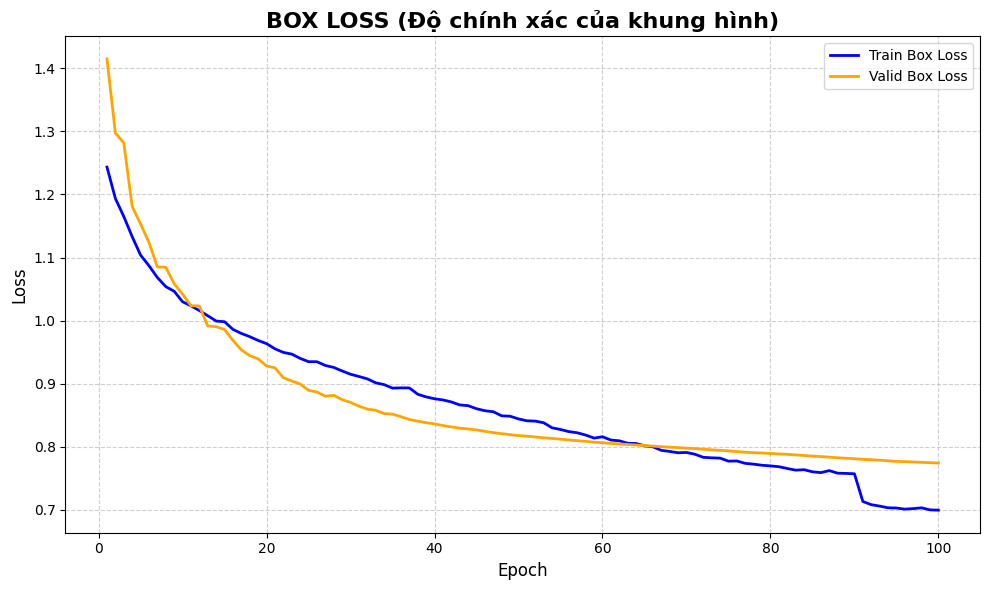

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import os

output_save_dir = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized')
os.makedirs(output_save_dir, exist_ok=True)
print(f"\n📂 Đích đến: {output_save_dir}\n")

# Đường dẫn tới file kết quả của YOLO
csv_path = os.path.join(output_save_dir, 'training_logs', 'results.csv')

if os.path.exists(csv_path):
    # Đọc dữ liệu và xóa khoảng trắng thừa ở tên cột (Chỉ cần làm 1 lần ở cell này)
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip() 

    # Vẽ biểu đồ Box Loss
    plt.figure(figsize=(10, 6))
    plt.plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', color='blue', linewidth=2)
    plt.plot(df['epoch'], df['val/box_loss'], label='Valid Box Loss', color='orange', linewidth=2)
    
    plt.title('BOX LOSS (Độ chính xác của khung hình)', fontsize=16, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()
else:
    print(f"❌ Không tìm thấy file {csv_path}. Bạn kiểm tra lại đường dẫn nhé!")

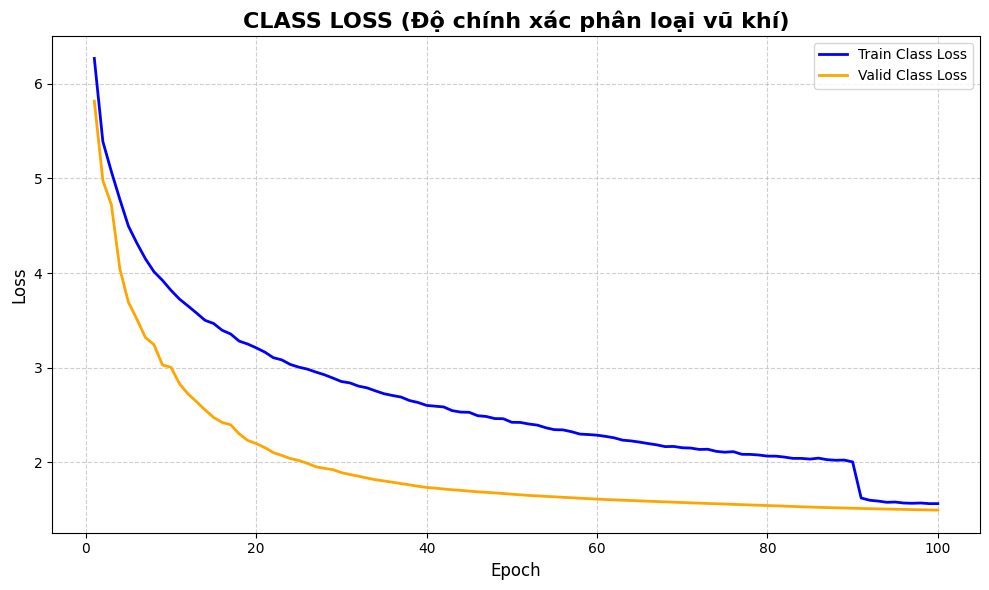

In [19]:
if 'df' in locals():
    plt.figure(figsize=(10, 6))
    
    # Vẽ biểu đồ Class Loss
    plt.plot(df['epoch'], df['train/cls_loss'], label='Train Class Loss', color='blue', linewidth=2)
    plt.plot(df['epoch'], df['val/cls_loss'], label='Valid Class Loss', color='orange', linewidth=2)
    
    plt.title('CLASS LOSS (Độ chính xác phân loại vũ khí)', fontsize=16, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()
else:
    print("❌ Chưa có dữ liệu. Vui lòng chạy Cell 1 trước để nạp file CSV!")

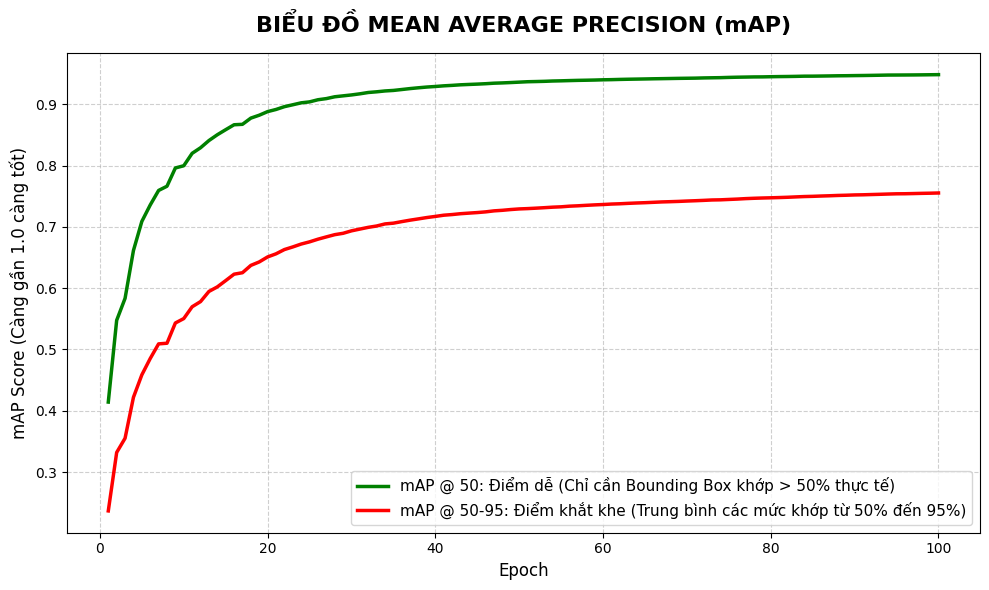

In [7]:
if 'df' in locals():
    # 3. Vẽ biểu đồ mAP
    plt.figure(figsize=(10, 6))
    
    # Định nghĩa chú thích rõ ràng bản chất của 2 đường
    label_map50 = 'mAP @ 50: Điểm dễ (Chỉ cần Bounding Box khớp > 50% thực tế)'
    label_map50_95 = 'mAP @ 50-95: Điểm khắt khe (Trung bình các mức khớp từ 50% đến 95%)'

    plt.plot(df['epoch'], df['metrics/mAP50(B)'], label=label_map50, color='green', linewidth=2.5)
    plt.plot(df['epoch'], df['metrics/mAP50-95(B)'], label=label_map50_95, color='red', linewidth=2.5)
    
    plt.title('BIỂU ĐỒ MEAN AVERAGE PRECISION (mAP)', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('mAP Score (Càng gần 1.0 càng tốt)', fontsize=12)
    
    # Kéo Legend xuống góc phải dưới để không đè lên đường đồ thị đang đi lên
    plt.legend(fontsize=11, loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("❌ Lỗi: Chưa có dữ liệu. Bạn hãy chạy Cell 1 trước nhé!")

## CONFUSION MATRIX

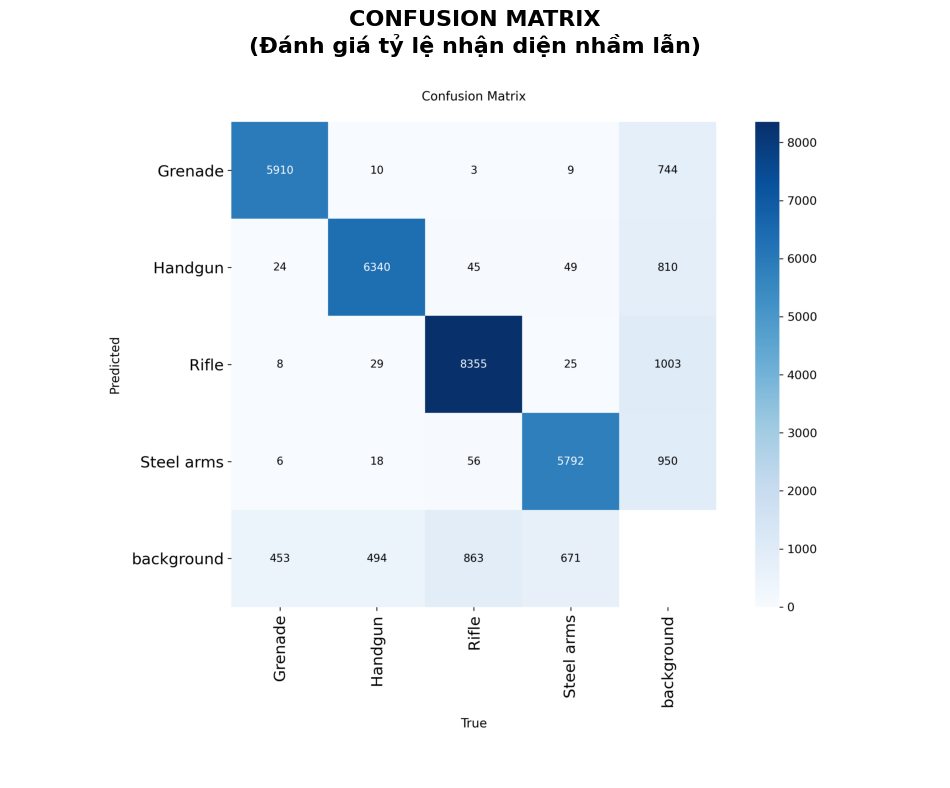

In [7]:
import cv2
import matplotlib.pyplot as plt
import os

cm_path = os.path.join(output_save_dir, 'training_logs', 'confusion_matrix.png')

if os.path.exists(cm_path):
    # Đọc ảnh bằng OpenCV và chuyển hệ màu BGR -> RGB
    img_cm = cv2.imread(cm_path)
    img_cm = cv2.cvtColor(img_cm, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 10))
    plt.imshow(img_cm)
    plt.axis('off') # Tắt trục tọa độ cho đẹp
    plt.title('CONFUSION MATRIX\n(Đánh giá tỷ lệ nhận diện nhầm lẫn)', fontsize=16, fontweight='bold', pad=20)
    plt.show()
else:
    print(f"❌ Không tìm thấy file {cm_path}.")

## PR CURVE

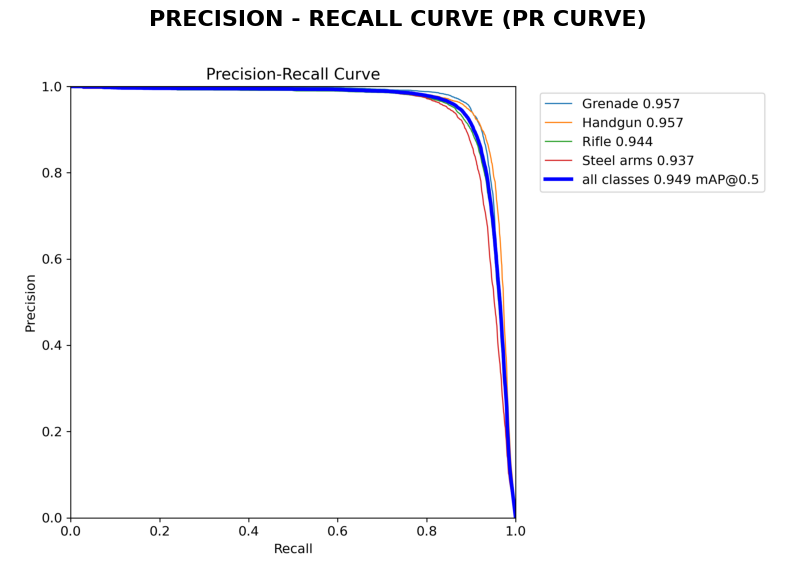

In [8]:
import cv2
import matplotlib.pyplot as plt
import os

# Đổi tên file thành 'BoxPR_curve.png' cho chuẩn với các bản Ultralytics mới
pr_path = os.path.join(output_save_dir, 'training_logs', 'BoxPR_curve.png')

if os.path.exists(pr_path):
    img_pr = cv2.imread(pr_path)
    img_pr = cv2.cvtColor(img_pr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 8))
    plt.imshow(img_pr)
    plt.axis('off')
    plt.title('PRECISION - RECALL CURVE (PR CURVE)', fontsize=16, fontweight='bold', pad=20)
    plt.show()
else:
    print(f"❌ Không tìm thấy file {pr_path}. Hãy kiểm tra lại thư mục logs!")

# SO SÁNH 2 MÔ HÌNH

## CHỈ SỐ

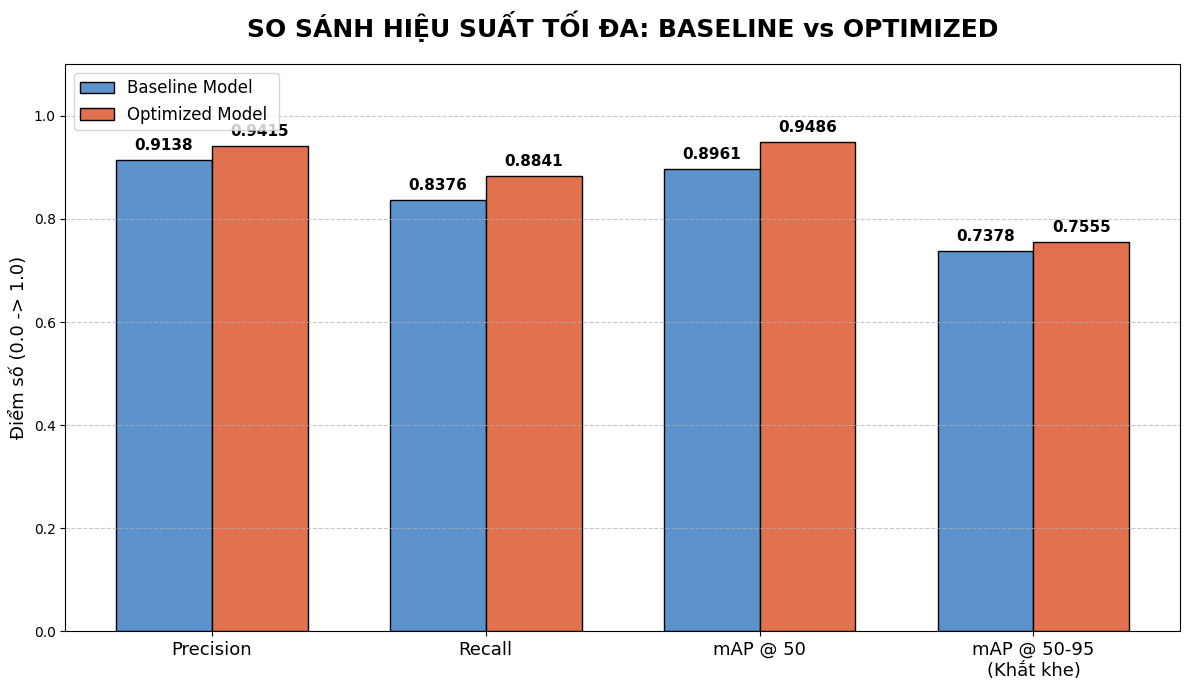

💾 Đã lưu biểu đồ so sánh tại: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\comparison_baseline_vs_optimized.png


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. ĐỊNH NGHĨA HÀM TRÍCH XUẤT BEST EPOCH
# ==========================================
def get_best_metrics(csv_path):
    if not os.path.exists(csv_path):
        return None
    
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip() 
    
    # Tính điểm Fitness (0.1 * mAP@50 + 0.9 * mAP@50-95)
    fitness_scores = 0.1 * df['metrics/mAP50(B)'] + 0.9 * df['metrics/mAP50-95(B)']
    best_idx = fitness_scores.idxmax()
    best_row = df.iloc[best_idx]
    
    return {
        'Precision': best_row['metrics/precision(B)'],
        'Recall': best_row['metrics/recall(B)'],
        'mAP@50': best_row['metrics/mAP50(B)'],
        'mAP@50-95': best_row['metrics/mAP50-95(B)']
    }

# ==========================================
# 2. ĐỌC DỮ LIỆU TỪ 2 MÔ HÌNH
# ==========================================
# Cập nhật đường dẫn thư mục theo code cũ của bạn
baseline_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models', 'training_logs', 'results.csv')
optimized_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized', 'training_logs', 'results.csv')

metrics_base = get_best_metrics(baseline_csv)
metrics_opt = get_best_metrics(optimized_csv)

if metrics_base is None or metrics_opt is None:
    print("❌ Lỗi: Không tìm thấy đủ 2 file CSV để so sánh. Vui lòng kiểm tra lại đường dẫn!")
else:
    # ==========================================
    # 3. VẼ BIỂU ĐỒ CỘT KÉP (GROUPED BAR CHART)
    # ==========================================
    labels = ['Precision', 'Recall', 'mAP @ 50', 'mAP @ 50-95\n(Khắt khe)']
    
    # Rút trích mảng giá trị
    base_values = [metrics_base['Precision'], metrics_base['Recall'], metrics_base['mAP@50'], metrics_base['mAP@50-95']]
    opt_values = [metrics_opt['Precision'], metrics_opt['Recall'], metrics_opt['mAP@50'], metrics_opt['mAP@50-95']]

    x = np.arange(len(labels))  # Vị trí của các nhóm cột
    width = 0.35                # Độ rộng của cột

    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Vẽ cột
    rects1 = ax.bar(x - width/2, base_values, width, label='Baseline Model ', color='#5C93CC', edgecolor='black')
    rects2 = ax.bar(x + width/2, opt_values, width, label='Optimized Model ', color='#E1714F', edgecolor='black')

    # Trang trí biểu đồ
    ax.set_ylabel('Điểm số (0.0 -> 1.0)', fontsize=13)
    ax.set_title('SO SÁNH HIỆU SUẤT TỐI ĐA: BASELINE vs OPTIMIZED', fontsize=18, fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=13)
    ax.set_ylim(0, 1.1) # Dư ra một chút để hiện số liệu trên đỉnh cột
    ax.legend(fontsize=12, loc='upper left')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Thêm text giá trị lên trên đỉnh mỗi cột
    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.4f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 5),  # Dịch lên 5 points
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=11, fontweight='bold')

    autolabel(rects1)
    autolabel(rects2)

    plt.tight_layout()
    
    # Lưu ảnh ra thư mục gốc
    save_path = os.path.join(OUTPUT_DATASET_PATH, 'comparison_baseline_vs_optimized.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"💾 Đã lưu biểu đồ so sánh tại: {save_path}")

## BIỂU ĐỒ LOSS

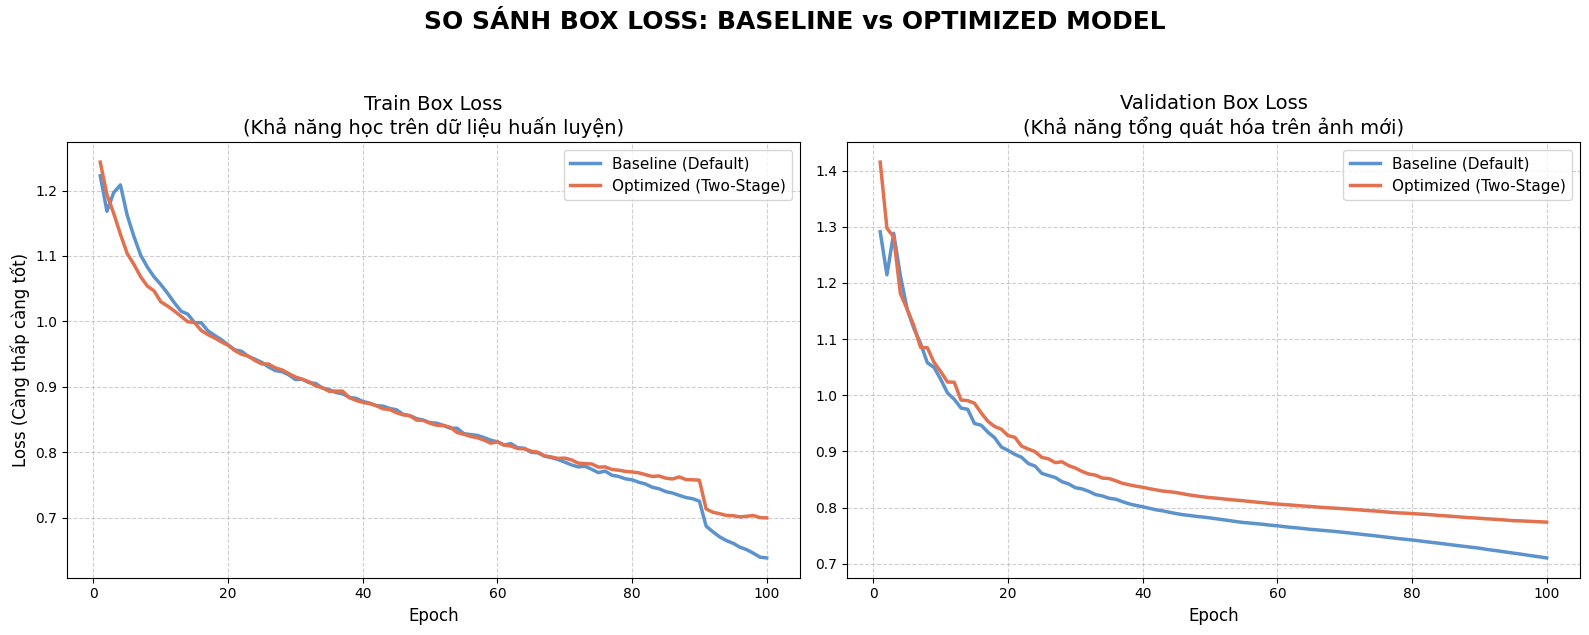

💾 Đã lưu biểu đồ so sánh Box Loss tại: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\comparison_box_loss_curves.png


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. ĐƯỜNG DẪN TỚI 2 FILE LOGS
# ==========================================
# (Đảm bảo biến OUTPUT_DATASET_PATH đã được khai báo ở các cell trước)
baseline_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models', 'training_logs', 'results.csv')
optimized_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized', 'training_logs', 'results.csv')

if os.path.exists(baseline_csv) and os.path.exists(optimized_csv):
    # ==========================================
    # 2. ĐỌC VÀ LÀM SẠCH DỮ LIỆU
    # ==========================================
    df_base = pd.read_csv(baseline_csv)
    df_base.columns = df_base.columns.str.strip()

    df_opt = pd.read_csv(optimized_csv)
    df_opt.columns = df_opt.columns.str.strip()

    # ==========================================
    # 3. VẼ BIỂU ĐỒ SO SÁNH (1 HÀNG, 2 CỘT)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('SO SÁNH BOX LOSS: BASELINE vs OPTIMIZED MODEL', fontsize=18, fontweight='bold', y=1.05)

    # Cài đặt màu sắc đồng nhất (Base: Xanh, Opt: Cam/Đỏ)
    color_base = '#5C93CC'
    color_opt = '#E1714F'

    # ---------- BIỂU ĐỒ 1: TRAIN BOX LOSS ----------
    axes[0].plot(df_base['epoch'], df_base['train/box_loss'], label='Baseline (Default)', color=color_base, linewidth=2.5)
    axes[0].plot(df_opt['epoch'], df_opt['train/box_loss'], label='Optimized (Two-Stage)', color=color_opt, linewidth=2.5)
    
    axes[0].set_title('Train Box Loss\n(Khả năng học trên dữ liệu huấn luyện)', fontsize=14)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss (Càng thấp càng tốt)', fontsize=12)
    axes[0].legend(fontsize=11)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # ---------- BIỂU ĐỒ 2: VALIDATION BOX LOSS ----------
    axes[1].plot(df_base['epoch'], df_base['val/box_loss'], label='Baseline (Default)', color=color_base, linewidth=2.5)
    axes[1].plot(df_opt['epoch'], df_opt['val/box_loss'], label='Optimized (Two-Stage)', color=color_opt, linewidth=2.5)
    
    axes[1].set_title('Validation Box Loss\n(Khả năng tổng quát hóa trên ảnh mới)', fontsize=14)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].legend(fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # ==========================================
    # 4. LƯU VÀ HIỂN THỊ
    # ==========================================
    save_path = os.path.join(OUTPUT_DATASET_PATH, 'comparison_box_loss_curves.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"💾 Đã lưu biểu đồ so sánh Box Loss tại: {save_path}")
else:
    print("❌ Lỗi: Không tìm thấy đủ 2 file CSV. Vui lòng kiểm tra lại đường dẫn của Baseline và Optimized!")

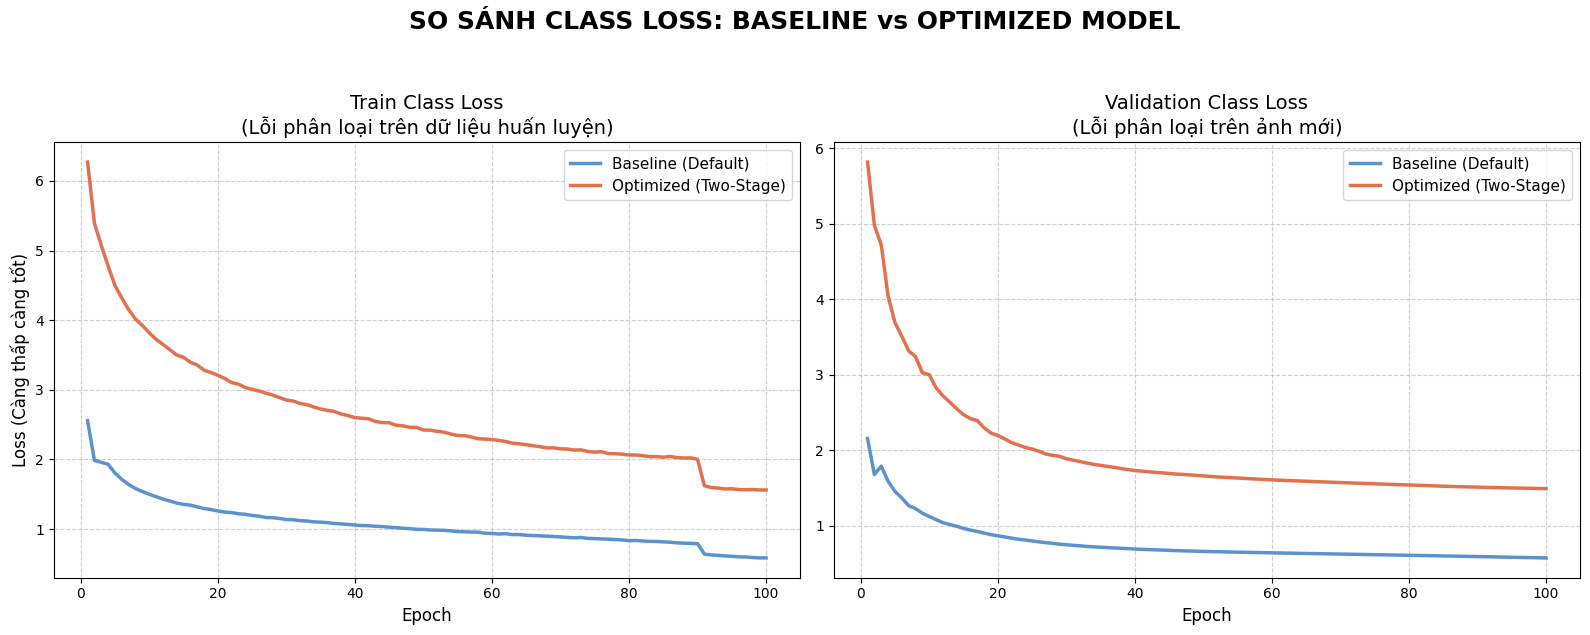

💾 Đã lưu biểu đồ so sánh Class Loss tại: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\comparison_cls_loss_curves.png


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. ĐƯỜNG DẪN TỚI 2 FILE LOGS
# ==========================================
# (Đảm bảo biến OUTPUT_DATASET_PATH đã được khai báo ở các cell trước)
baseline_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models', 'training_logs', 'results.csv')
optimized_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized', 'training_logs', 'results.csv') 

if os.path.exists(baseline_csv) and os.path.exists(optimized_csv):
    # ==========================================
    # 2. ĐỌC VÀ LÀM SẠCH DỮ LIỆU
    # ==========================================
    df_base = pd.read_csv(baseline_csv)
    df_base.columns = df_base.columns.str.strip()

    df_opt = pd.read_csv(optimized_csv)
    df_opt.columns = df_opt.columns.str.strip()

    # ==========================================
    # 3. VẼ BIỂU ĐỒ SO SÁNH (1 HÀNG, 2 CỘT)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('SO SÁNH CLASS LOSS: BASELINE vs OPTIMIZED MODEL', fontsize=18, fontweight='bold', y=1.05)

    # Cài đặt màu sắc đồng nhất (Base: Xanh, Opt: Cam/Đỏ)
    color_base = '#5C93CC'
    color_opt = '#E1714F'

    # ---------- BIỂU ĐỒ 1: TRAIN CLASS LOSS ----------
    # THAY ĐỔI: box_loss -> cls_loss
    axes[0].plot(df_base['epoch'], df_base['train/cls_loss'], label='Baseline (Default)', color=color_base, linewidth=2.5)
    axes[0].plot(df_opt['epoch'], df_opt['train/cls_loss'], label='Optimized (Two-Stage)', color=color_opt, linewidth=2.5)
    
    axes[0].set_title('Train Class Loss\n(Lỗi phân loại trên dữ liệu huấn luyện)', fontsize=14)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss (Càng thấp càng tốt)', fontsize=12)
    axes[0].legend(fontsize=11)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # ---------- BIỂU ĐỒ 2: VALIDATION CLASS LOSS ----------
    # THAY ĐỔI: box_loss -> cls_loss
    axes[1].plot(df_base['epoch'], df_base['val/cls_loss'], label='Baseline (Default)', color=color_base, linewidth=2.5)
    axes[1].plot(df_opt['epoch'], df_opt['val/cls_loss'], label='Optimized (Two-Stage)', color=color_opt, linewidth=2.5)
    
    axes[1].set_title('Validation Class Loss\n(Lỗi phân loại trên ảnh mới)', fontsize=14)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].legend(fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # ==========================================
    # 4. LƯU VÀ HIỂN THỊ
    # ==========================================
    # THAY ĐỔI: Đổi tên file lưu để không đè lên hình Box Loss
    save_path = os.path.join(OUTPUT_DATASET_PATH, 'comparison_cls_loss_curves.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"💾 Đã lưu biểu đồ so sánh Class Loss tại: {save_path}")
else:
    print("❌ Lỗi: Không tìm thấy đủ 2 file CSV. Vui lòng kiểm tra lại đường dẫn của Baseline và Optimized!")

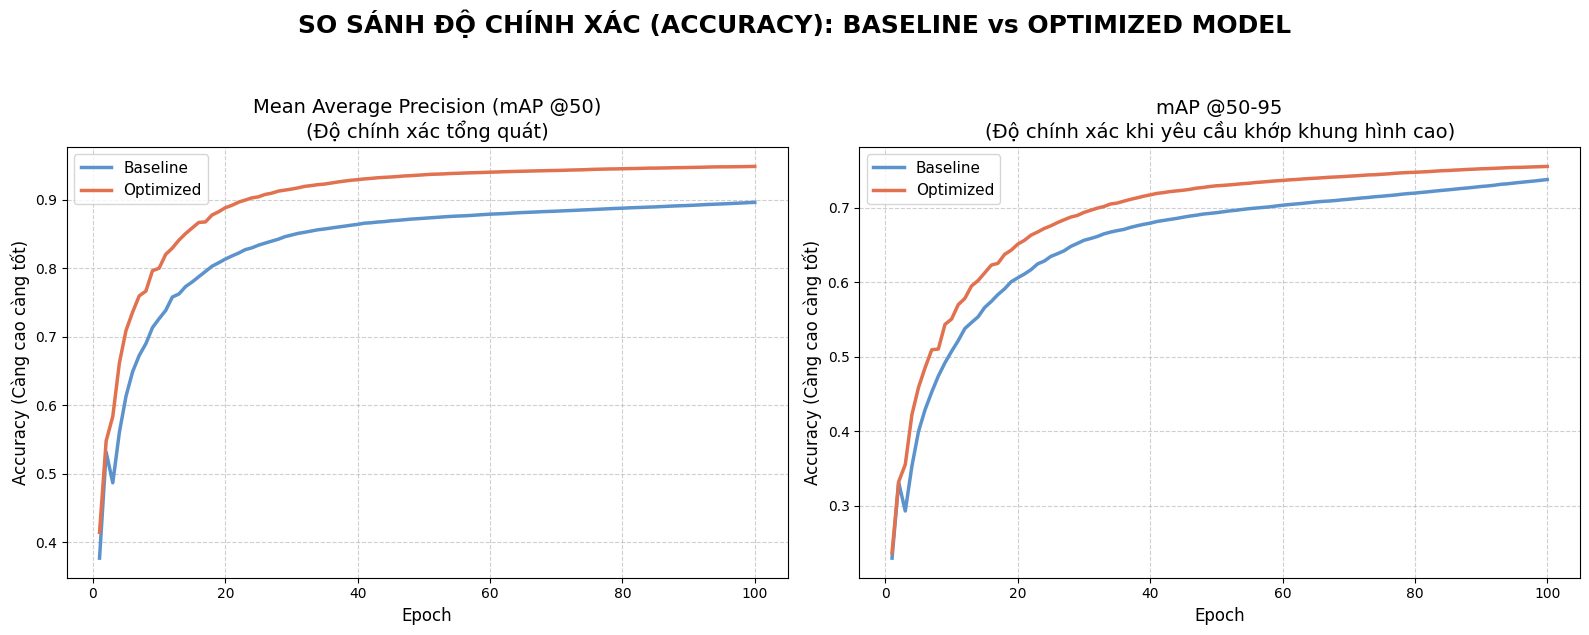

💾 Đã lưu biểu đồ so sánh Accuracy tại: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\comparison_accuracy_curves.png


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. ĐƯỜNG DẪN TỚI 2 FILE LOGS
# ==========================================
baseline_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models', 'training_logs', 'results.csv')
optimized_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized', 'training_logs', 'results.csv') 

if os.path.exists(baseline_csv) and os.path.exists(optimized_csv):
    # ==========================================
    # 2. ĐỌC VÀ LÀM SẠCH DỮ LIỆU
    # ==========================================
    df_base = pd.read_csv(baseline_csv)
    df_base.columns = df_base.columns.str.strip()

    df_opt = pd.read_csv(optimized_csv)
    df_opt.columns = df_opt.columns.str.strip()

    # ==========================================
    # 3. VÈ BIỂU ĐỒ SO SÁNH (1 HÀNG, 2 CỘT)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY): BASELINE vs OPTIMIZED MODEL', fontsize=18, fontweight='bold', y=1.05)

    # Cài đặt màu sắc đồng nhất (Base: Xanh, Opt: Đỏ cam)
    color_base = '#5C93CC'
    color_opt = '#E1714F'

    # ---------- BIỂU ĐỒ 1: mAP50 (Độ chính xác tổng quát) ----------
    # 'metrics/mAP50(B)' = Khả năng nhận diện đúng vật thể ở ngưỡng khớp 50%
    axes[0].plot(df_base['epoch'], df_base['metrics/mAP50(B)'], label='Baseline', color=color_base, linewidth=2.5)
    axes[0].plot(df_opt['epoch'], df_opt['metrics/mAP50(B)'], label='Optimized', color=color_opt, linewidth=2.5)
    
    axes[0].set_title('Mean Average Precision (mAP @50)\n(Độ chính xác tổng quát)', fontsize=14)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Accuracy (Càng cao càng tốt)', fontsize=12) # Accuracy tăng dần theo thời gian
    axes[0].legend(fontsize=11)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # ---------- BIỂU ĐỒ 2: mAP50-95 (Độ chính xác khắt khe) ----------
    # 'metrics/mAP50-95(B)' = Độ chính xác trung bình trên nhiều ngưỡng khớp (khó hơn)
    axes[1].plot(df_base['epoch'], df_base['metrics/mAP50-95(B)'], label='Baseline', color=color_base, linewidth=2.5)
    axes[1].plot(df_opt['epoch'], df_opt['metrics/mAP50-95(B)'], label='Optimized', color=color_opt, linewidth=2.5)
    
    axes[1].set_title('mAP @50-95\n(Độ chính xác khi yêu cầu khớp khung hình cao)', fontsize=14)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Accuracy (Càng cao càng tốt)', fontsize=12) # Accuracy tăng dần theo thời gian
    axes[1].legend(fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # ==========================================
    # 4. LƯU VÀ HIỂN THỊ
    # ==========================================
    # Đổi tên file lưu sang Accuracy
    save_path = os.path.join(OUTPUT_DATASET_PATH, 'comparison_accuracy_curves.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"💾 Đã lưu biểu đồ so sánh Accuracy tại: {save_path}")
else:
    print("❌ Lỗi: Không tìm thấy đủ 2 file CSV. Vui lòng kiểm tra lại đường dẫn!")

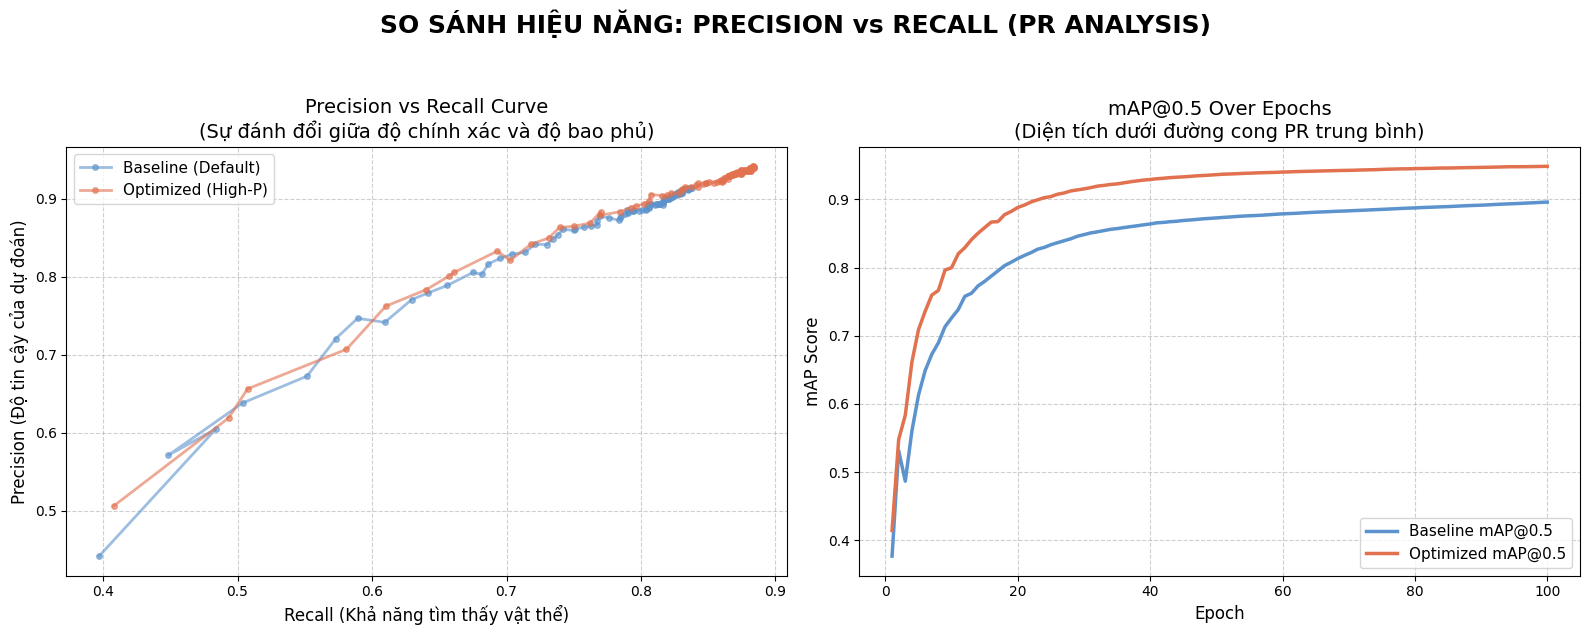

💾 Đã lưu biểu đồ so sánh PR Performance tại: D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\comparison_pr_performance.png


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. ĐƯỜNG DẪN TỚI 2 FILE LOGS
# ==========================================
baseline_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models', 'training_logs', 'results.csv')
optimized_csv = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_optimized', 'training_logs', 'results.csv') 

if os.path.exists(baseline_csv) and os.path.exists(optimized_csv):
    # ==========================================
    # 2. ĐỌC VÀ LÀM SẠCH DỮ LIỆU
    # ==========================================
    df_base = pd.read_csv(baseline_csv)
    df_base.columns = df_base.columns.str.strip()

    df_opt = pd.read_csv(optimized_csv)
    df_opt.columns = df_opt.columns.str.strip()

    # ==========================================
    # 3. VẼ BIỂU ĐỒ SO SÁNH (1 HÀNG, 2 CỘT)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('SO SÁNH HIỆU NĂNG: PRECISION vs RECALL (PR ANALYSIS)', fontsize=18, fontweight='bold', y=1.05)

    # Cài đặt màu sắc
    color_base = '#5C93CC' # Xanh
    color_opt = '#E1714F'  # Cam

    # ---------- BIỂU ĐỒ 1: PRECISION vs RECALL CURVE ----------
    # Trục X là Recall, Trục Y là Precision
    axes[0].plot(df_base['metrics/recall(B)'], df_base['metrics/precision(B)'], label='Baseline (Default)', color=color_base, linewidth=2, marker='o', markersize=4, alpha=0.6)
    axes[0].plot(df_opt['metrics/recall(B)'], df_opt['metrics/precision(B)'], label='Optimized (High-P)', color=color_opt, linewidth=2, marker='o', markersize=4, alpha=0.6)
    
    axes[0].set_title('Precision vs Recall Curve\n(Sự đánh đổi giữa độ chính xác và độ bao phủ)', fontsize=14)
    axes[0].set_xlabel('Recall (Khả năng tìm thấy vật thể)', fontsize=12)
    axes[0].set_ylabel('Precision (Độ tin cậy của dự đoán)', fontsize=12)
    axes[0].legend(fontsize=11)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # ---------- BIỂU ĐỒ 2: mAP@0.5 OVER EPOCHS ----------
    # Biểu đồ này bổ trợ để thấy sự ổn định của PR qua thời gian
    axes[1].plot(df_base['epoch'], df_base['metrics/mAP50(B)'], label='Baseline mAP@0.5', color=color_base, linewidth=2.5)
    axes[1].plot(df_opt['epoch'], df_opt['metrics/mAP50(B)'], label='Optimized mAP@0.5', color=color_opt, linewidth=2.5)
    
    axes[1].set_title('mAP@0.5 Over Epochs\n(Diện tích dưới đường cong PR trung bình)', fontsize=14)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('mAP Score', fontsize=12)
    axes[1].legend(fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # ==========================================
    # 4. LƯU VÀ HIỂN THỊ
    # ==========================================
    save_path = os.path.join(OUTPUT_DATASET_PATH, 'comparison_pr_performance.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"💾 Đã lưu biểu đồ so sánh PR Performance tại: {save_path}")
else:
    print("❌ Lỗi: Không tìm thấy đủ 2 file CSV. Vui lòng kiểm tra lại đường dẫn!")

# TEST

## TEST ẢNH

🚀 Đang khởi tạo 2 mô hình...
🔍 Đang thực hiện nhận diện...

0: 640x640 3 Handguns, 2 Rifles, 1 Steel arms, 5.9ms
1: 640x640 3 Handguns, 1 Rifle, 5.9ms
2: 640x640 3 Grenades, 5.9ms
3: 640x640 3 Handguns, 10 Rifles, 5.9ms
4: 640x640 1 Rifle, 5.9ms
5: 640x640 1 Handgun, 5.9ms
Speed: 2.0ms preprocess, 5.9ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 3 Handguns, 2 Rifles, 1 Steel arms, 5.7ms
1: 640x640 3 Handguns, 1 Rifle, 5.7ms
2: 640x640 3 Grenades, 5.7ms
3: 640x640 6 Handguns, 8 Rifles, 5.7ms
4: 640x640 1 Rifle, 5.7ms
5: 640x640 1 Handgun, 5.7ms
Speed: 2.2ms preprocess, 5.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


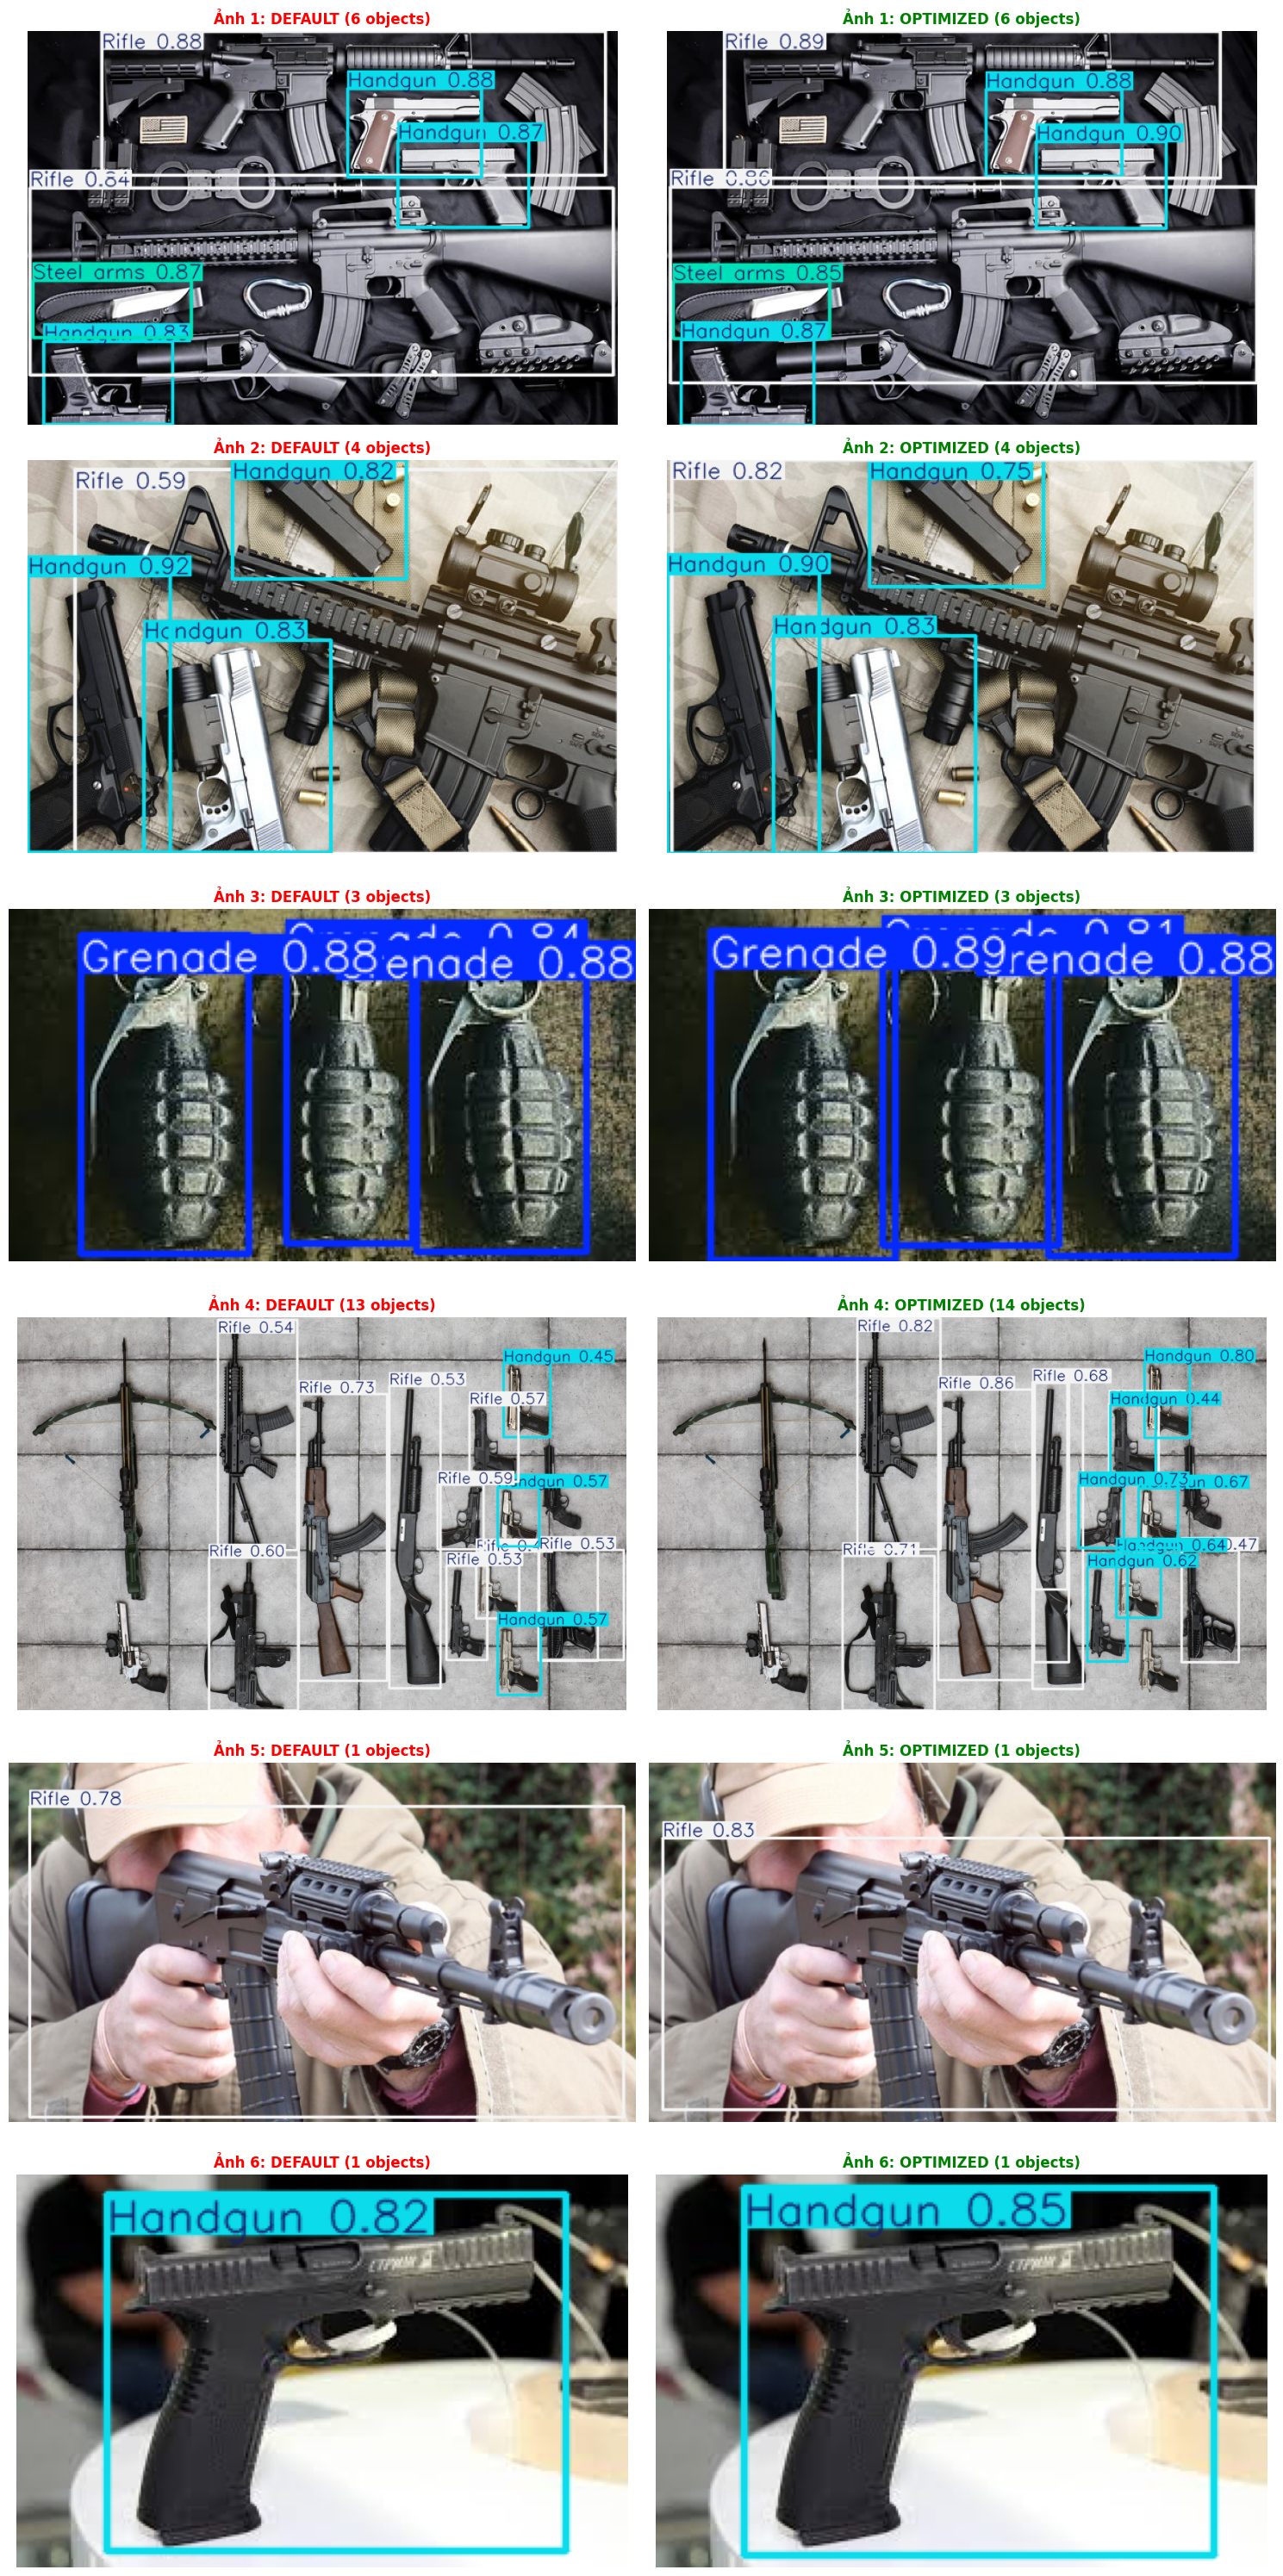


✅ Đã hiển thị so sánh. Hãy quan sát sự khác biệt về Precision và các khung nhận diện!


In [14]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# =============================================================================
# SO SÁNH YOLO: DEFAULT VS HIGH-PRECISION OPTIMIZATION
# =============================================================================

# 1. CẤU HÌNH ĐƯỜNG DẪN MÔ HÌNH
MODEL_DEFAULT_PATH = r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\trained_models\best.pt"
MODEL_OPT_PATH     = r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\trained_models_optimized\best.pt"

CONF_THRESH = 0.4  # Ngưỡng tin cậy (Dùng chung để công bằng)

# Danh sách ảnh test (Giữ nguyên 8 ảnh của bạn)
IMG_PATHS = [
    r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Anh\1.jpg", 
    r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Anh\2.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Anh\3.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Anh\4.png", 
    r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Anh\5.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Anh\6.jpg"
]

# 2. LOAD VÀ CHẠY PREDICT CHO CẢ 2 MÔ HÌNH
print("🚀 Đang khởi tạo 2 mô hình...")
model_default = YOLO(MODEL_DEFAULT_PATH)
model_opt     = YOLO(MODEL_OPT_PATH)

print("🔍 Đang thực hiện nhận diện...")
results_default = model_default.predict(source=IMG_PATHS, conf=CONF_THRESH)
results_opt     = model_opt.predict(source=IMG_PATHS, conf=CONF_THRESH)

# 3. HIỂN THỊ SO SÁNH TRÊN LƯỚI
# Chúng ta sẽ tạo lưới: Hàng = Số lượng ảnh (8), Cột = 2 (Cột 1: Default, Cột 2: Optimized)
num_imgs = len(IMG_PATHS)
fig, axes = plt.subplots(num_imgs, 2, figsize=(15, 5 * num_imgs))

for i in range(num_imgs):
    # --- Xử lý ảnh của Model Default ---
    img_def_bgr = results_default[i].plot()
    img_def_rgb = cv2.cvtColor(img_def_bgr, cv2.COLOR_BGR2RGB)
    num_obj_def = len(results_default[i].boxes)
    
    axes[i, 0].imshow(img_def_rgb)
    axes[i, 0].set_title(f"Ảnh {i+1}: DEFAULT ({num_obj_def} objects)", color='red', fontweight='bold')
    axes[i, 0].axis('off')

    # --- Xử lý ảnh của Model Optimized ---
    img_opt_bgr = results_opt[i].plot()
    img_opt_rgb = cv2.cvtColor(img_opt_bgr, cv2.COLOR_BGR2RGB)
    num_obj_opt = len(results_opt[i].boxes)
    
    axes[i, 1].imshow(img_opt_rgb)
    axes[i, 1].set_title(f"Ảnh {i+1}: OPTIMIZED ({num_obj_opt} objects)", color='green', fontweight='bold')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

print("\n✅ Đã hiển thị so sánh. Hãy quan sát sự khác biệt về Precision và các khung nhận diện!")

## TEST VIDEO

In [15]:
import os
from ultralytics import YOLO

# =============================================================================
# DEMO YOLO11s: NHẬN DIỆN TRÊN 1 VIDEO VỚI 2 MÔ HÌNH
# =============================================================================

# 1. CẤU HÌNH PARAMETERS
# Định nghĩa danh sách các mô hình bạn muốn chạy
MODELS_CONFIG = {
    "YOLO11s_Base": r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\trained_models\best.pt",
    "YOLO11s_Optimized": r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\trained_models_optimized\best.pt"
}

VIDEO_PATH = r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4" 
SAVE_DIR = r"D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo"
CONF_THRESH = 0.45  # Ngưỡng tin cậy

# 2. CHẠY INFERENCE LẦN LƯỢT QUA TỪNG MODEL
print(f"🎬 Bắt đầu quy trình so sánh mô hình trên Video...")

for model_name, model_path in MODELS_CONFIG.items():
    if not os.path.exists(model_path):
        print(f"⚠️ Cảnh báo: Không tìm thấy file trọng số tại {model_path}. Bỏ qua...")
        continue

    print(f"\n🚀 Đang xử lý bằng mô hình: {model_name}")
    
    # Khởi tạo model
    model = YOLO(model_path)

    # Chạy dự đoán
    # Lưu kết quả vào thư mục con mang tên của chính model đó
    results = model.predict(
        source=VIDEO_PATH,
        conf=CONF_THRESH,
        save=True,              # Lưu video kết quả
        project=SAVE_DIR,       # Thư mục gốc để lưu
        name=model_name,        # Tên thư mục con (ví dụ: YOLO11s_Base)
        exist_ok=True,          # Ghi đè nếu thư mục đã tồn tại
        stream=True,            # Tối ưu RAM bằng cách xử lý từng frame (Generator)
        device='0'              # '0' = GPU, 'cpu' = CPU
    )

    # Kích hoạt vòng lặp xử lý từng khung hình (bắt buộc khi dùng stream=True)
    for r in results:
        pass

    print(f"✅ Đã lưu video từ {model_name} tại: {os.path.join(SAVE_DIR, model_name)}")

print("\n" + "="*50)
print("🏁 TẤT CẢ CÁC MÔ HÌNH ĐÃ XỬ LÝ XONG!")
print("="*50)

🎬 Bắt đầu quy trình so sánh mô hình trên Video...

🚀 Đang xử lý bằng mô hình: YOLO11s_Base

video 1/1 (frame 1/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 57.0ms
video 1/1 (frame 2/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 13.0ms
video 1/1 (frame 3/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 12.4ms
video 1/1 (frame 4/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 12.3ms
video 1/1 (frame 5/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 12.4ms
video 1/1 (frame 6/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 13.9ms
video 1/1 (frame 7/1803) D:\Stuffs\ThiGiacMayTinh\HocSau\WeaponHocSau\demo\Video\test.mp4: 384x640 (no detections), 9.7ms
video 1/1 (frame 8/1803) D:\Stuffs\ThiGiacMayTin